# OMOP CDM — SNUH Synthetic Dataset Analysis
**Database:** `data/synthetic_snuh.duckdb`  
**Schema:** `main`  
**Vocabularies:** SNOMED, RxNorm, LOINC, ICD10, KCD7, KDC, KNHIS

In [14]:
import duckdb
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import warnings
warnings.filterwarnings('ignore')

pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', 60)
pd.set_option('display.float_format', '{:,.1f}'.format)

DB_PATH = r'c:\Users\33633\Desktop\Efrei\M2\Stage\K-OMOP-CDM\data\synthetic_snuh.duckdb'
con = duckdb.connect(DB_PATH, read_only=True)
print('Connected to:', DB_PATH)

Connected to: c:\Users\33633\Desktop\Efrei\M2\Stage\K-OMOP-CDM\data\synthetic_snuh.duckdb


## 1. Database Overview

In [2]:
tables = con.execute("""
    SELECT table_name, 
           CASE WHEN table_name IN ('concept','concept_relationship','concept_ancestor',
                                    'vocabulary','concept_synonym','drug_strength',
                                    'domain','concept_class','relationship')
                THEN 'Vocabulary' ELSE 'Clinical' END AS category
    FROM information_schema.tables
    WHERE table_schema = 'main'
    ORDER BY category, table_name
""").df()

rows = []
for _, r in tables.iterrows():
    n = con.execute(f'SELECT COUNT(*) FROM main."{r.table_name}"').fetchone()[0]
    rows.append({'table': r.table_name, 'category': r.category, 'row_count': n})

df_tables = pd.DataFrame(rows)
df_tables['row_count'] = df_tables['row_count'].map('{:,}'.format)
df_tables.style.set_caption('All Tables').set_properties(**{'text-align': 'left'})

,table,category,row_count
0,care_site,Clinical,16
1,condition_occurrence,Clinical,"177,729"
2,death,Clinical,670
3,drug_exposure,Clinical,"205,917"
4,hospital_resource_event,Clinical,"1,961"
5,location,Clinical,16
6,measurement,Clinical,"205,094"
7,note,Clinical,"178,079"
8,note_llm_log,Clinical,"178,070"
9,note_text_template,Clinical,0


## 2. Patient Demographics

In [3]:
total_patients = con.execute('SELECT COUNT(*) FROM main.person').fetchone()[0]
print(f'Total patients: {total_patients:,}')

df_person = con.execute("""
    SELECT p.person_id,
           p.year_of_birth,
           p.gender_source_value,
           p.race_source_value,
           c_gender.concept_name AS gender_concept,
           c_race.concept_name   AS race_concept
    FROM main.person p
    LEFT JOIN main.concept c_gender ON p.gender_concept_id = c_gender.concept_id
    LEFT JOIN main.concept c_race   ON p.race_concept_id   = c_race.concept_id
    LIMIT 10
""").df()
df_person

Total patients: 10,000


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,person_id,year_of_birth,gender_source_value,race_source_value,gender_concept,race_concept
0,10000,1937,F,Korean,FEMALE,Asian
1,9999,1954,M,Korean,MALE,Asian
2,9998,1976,F,Korean,FEMALE,Asian
3,9997,1970,M,Korean,MALE,Asian
4,9996,1962,F,Korean,FEMALE,Asian
5,9995,1972,M,Korean,MALE,Asian
6,9992,1984,F,Korean,FEMALE,Asian
7,9994,1977,M,Korean,MALE,Asian
8,9981,1973,F,Korean,FEMALE,Asian
9,9993,1970,M,Korean,MALE,Asian


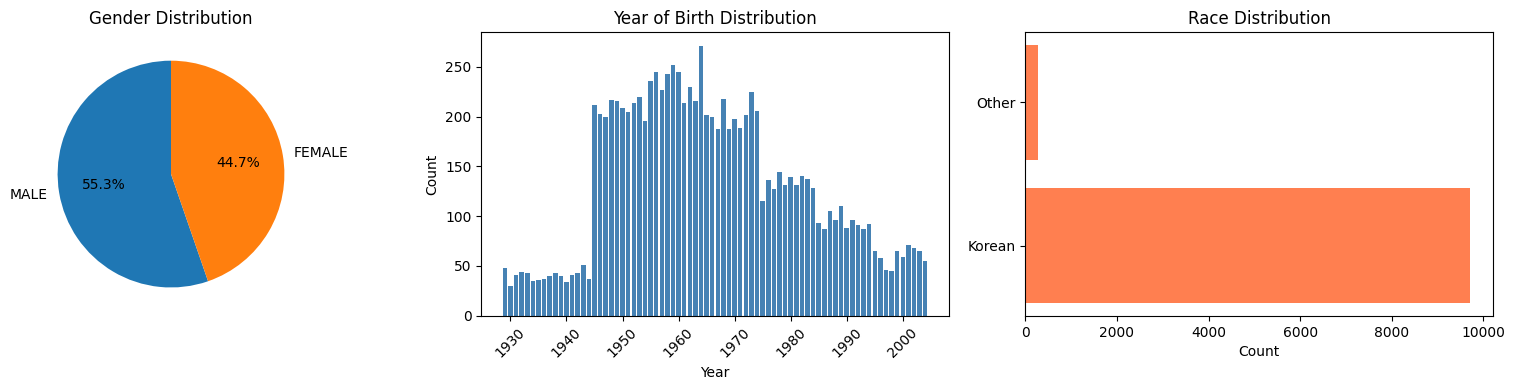

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# Gender distribution
df_gender = con.execute("""
    SELECT COALESCE(c.concept_name, 'Unknown') AS gender, COUNT(*) AS n
    FROM main.person p
    LEFT JOIN main.concept c ON p.gender_concept_id = c.concept_id
    GROUP BY 1 ORDER BY 2 DESC
""").df()
axes[0].pie(df_gender['n'], labels=df_gender['gender'], autopct='%1.1f%%', startangle=90)
axes[0].set_title('Gender Distribution')

# Year of birth
df_yob = con.execute("""
    SELECT year_of_birth, COUNT(*) AS n
    FROM main.person
    GROUP BY year_of_birth ORDER BY year_of_birth
""").df()
axes[1].bar(df_yob['year_of_birth'], df_yob['n'], color='steelblue', width=0.8)
axes[1].set_title('Year of Birth Distribution')
axes[1].set_xlabel('Year')
axes[1].set_ylabel('Count')
axes[1].tick_params(axis='x', rotation=45)

# Race distribution
df_race = con.execute("""
    SELECT COALESCE(race_source_value, 'Unknown') AS race, COUNT(*) AS n
    FROM main.person
    GROUP BY 1 ORDER BY 2 DESC
    LIMIT 6
""").df()
axes[2].barh(df_race['race'], df_race['n'], color='coral')
axes[2].set_title('Race Distribution')
axes[2].set_xlabel('Count')

plt.tight_layout()
plt.show()

## 3. Clinical Events Summary

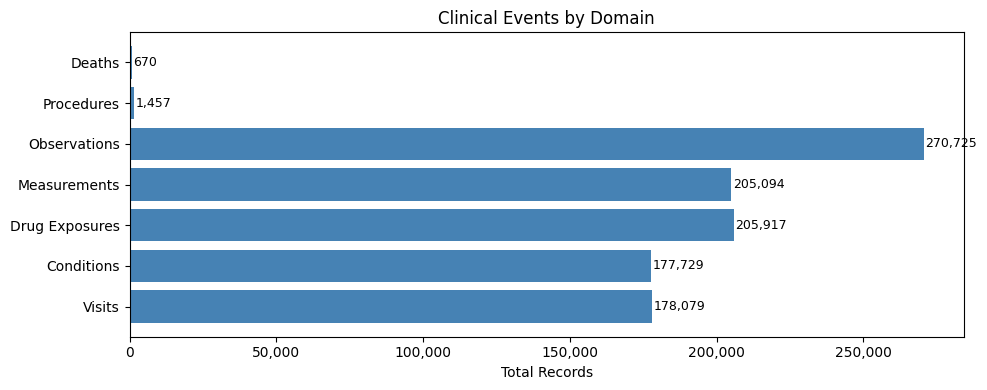

,Domain,Total Records,Per Patient
0,Visits,"178,079",17.8
1,Conditions,"177,729",17.8
2,Drug Exposures,"205,917",20.6
3,Measurements,"205,094",20.5
4,Observations,"270,725",27.1
5,Procedures,"1,457",0.1
6,Deaths,670,0.1


In [5]:
event_tables = [
    ('visit_occurrence',     'Visits'),
    ('condition_occurrence', 'Conditions'),
    ('drug_exposure',        'Drug Exposures'),
    ('measurement',          'Measurements'),
    ('observation',          'Observations'),
    ('procedure_occurrence', 'Procedures'),
    ('death',                'Deaths'),
]

rows = []
for table, label in event_tables:
    n = con.execute(f'SELECT COUNT(*) FROM main.{table}').fetchone()[0]
    rows.append({'Domain': label, 'Total Records': n, 'Per Patient': round(n / total_patients, 1)})

df_events = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(10, 4))
bars = ax.barh(df_events['Domain'], df_events['Total Records'], color='steelblue')
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{int(x):,}'))
ax.set_xlabel('Total Records')
ax.set_title('Clinical Events by Domain')
for bar, val in zip(bars, df_events['Total Records']):
    ax.text(bar.get_width() + 500, bar.get_y() + bar.get_height()/2,
            f'{val:,}', va='center', fontsize=9)
plt.tight_layout()
plt.show()

df_events['Total Records'] = df_events['Total Records'].map('{:,}'.format)
df_events

## 4. Concept Mapping Quality

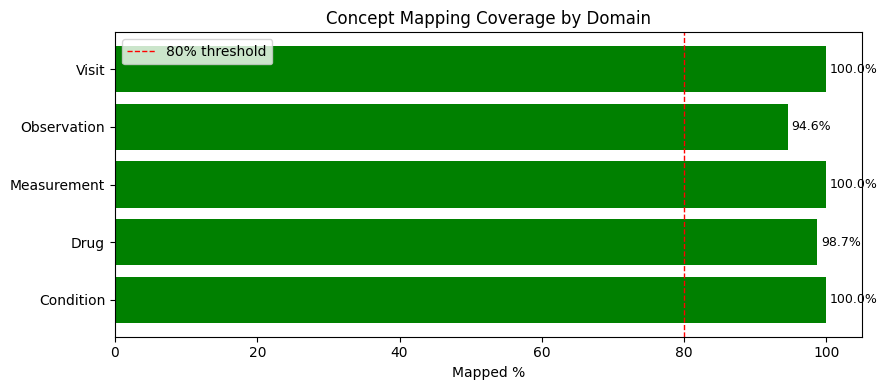

,Domain,Total,Non-zero (%),Standard (%),Unmapped
0,Condition,177729,100.0%,100.0%,0
1,Drug,205917,98.7%,86.3%,2761
2,Measurement,205094,100.0%,100.0%,0
3,Observation,270725,94.6%,100.0%,14575
4,Visit,178079,100.0%,100.0%,0


In [6]:
checks = [
    ('condition_occurrence', 'condition_concept_id',  'Condition'),
    ('drug_exposure',        'drug_concept_id',        'Drug'),
    ('measurement',          'measurement_concept_id', 'Measurement'),
    ('observation',          'observation_concept_id', 'Observation'),
    ('visit_occurrence',     'visit_concept_id',       'Visit'),
]

rows = []
for table, col, domain in checks:
    total   = con.execute(f'SELECT COUNT(*) FROM main.{table}').fetchone()[0]
    nonzero = con.execute(f'SELECT COUNT(*) FROM main.{table} WHERE {col} != 0').fetchone()[0]
    std     = con.execute(f"""
        SELECT COUNT(*) FROM main.{table} t
        JOIN main.concept c ON t.{col} = c.concept_id
        WHERE t.{col} != 0 AND c.standard_concept = 'S'
    """).fetchone()[0]
    rows.append({
        'Domain':         domain,
        'Total':          total,
        'Non-zero (%)':   f"{nonzero/total*100:.1f}%",
        'Standard (%)':   f"{std/nonzero*100:.1f}%" if nonzero > 0 else 'N/A',
        'Unmapped':       total - nonzero,
    })

df_cov = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(9, 4))
domains = [r['Domain'] for r in rows]
mapped_pct = [float(r['Non-zero (%)'].strip('%')) for r in rows]
colors = ['green' if p >= 90 else 'orange' if p >= 70 else 'red' for p in mapped_pct]
ax.barh(domains, mapped_pct, color=colors)
ax.axvline(80, color='red', linestyle='--', linewidth=1, label='80% threshold')
ax.set_xlim(0, 105)
ax.set_xlabel('Mapped %')
ax.set_title('Concept Mapping Coverage by Domain')
ax.legend()
for i, (p, c) in enumerate(zip(mapped_pct, colors)):
    ax.text(p + 0.5, i, f'{p:.1f}%', va='center', fontsize=9)
plt.tight_layout()
plt.show()

df_cov

## 5. Conditions Analysis

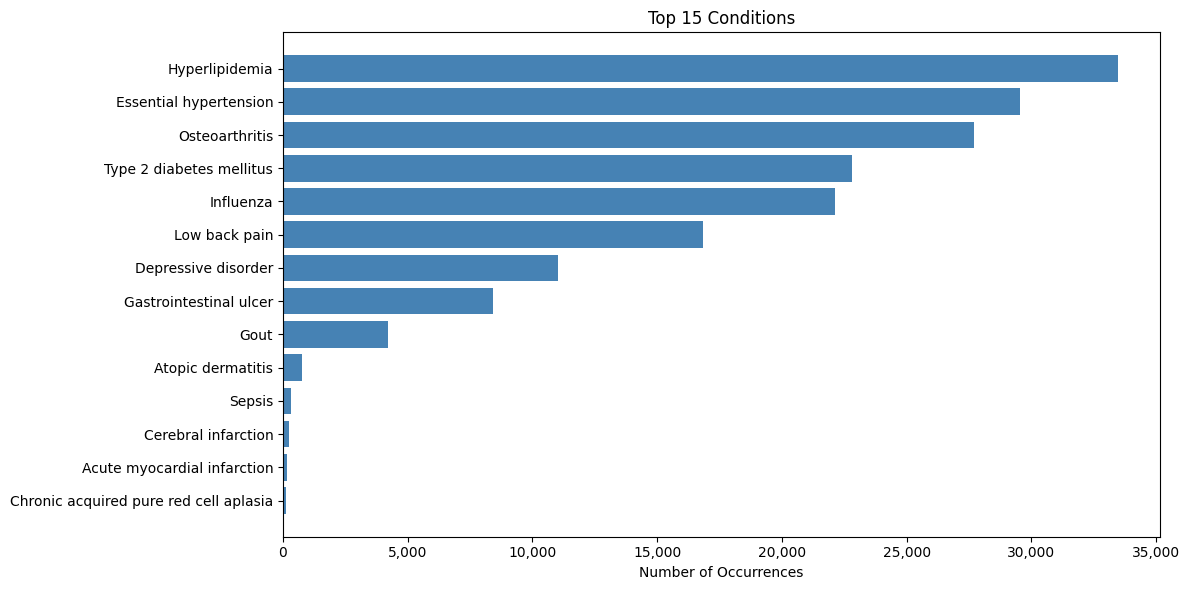

,condition,icd_code,n_occurrences,n_patients
0,Hyperlipidemia,E78,33464,6675
1,Essential hypertension,I10,29548,4218
2,Osteoarthritis,M17,27702,4637
3,Type 2 diabetes mellitus,E11,22803,3256
4,Influenza,J00,22123,4424
5,Low back pain,M54,16843,3382
6,Depressive disorder,F32,11009,1376
7,Gastrointestinal ulcer,K29,8426,2708
8,Gout,J30,4193,1180
9,Atopic dermatitis,L20,760,189


In [7]:
# Top 15 conditions
df_cond = con.execute("""
    SELECT c.concept_name AS condition,
           co.condition_source_value AS icd_code,
           COUNT(*) AS n_occurrences,
           COUNT(DISTINCT co.person_id) AS n_patients
    FROM main.condition_occurrence co
    JOIN main.concept c ON co.condition_concept_id = c.concept_id
    WHERE co.condition_concept_id != 0
    GROUP BY 1, 2
    ORDER BY n_occurrences DESC
    LIMIT 15
""").df()

fig, ax = plt.subplots(figsize=(12, 6))
ax.barh(df_cond['condition'][::-1], df_cond['n_occurrences'][::-1], color='steelblue')
ax.set_xlabel('Number of Occurrences')
ax.set_title('Top 15 Conditions')
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{int(x):,}'))
plt.tight_layout()
plt.show()

df_cond

## 6. Drug Exposure Analysis

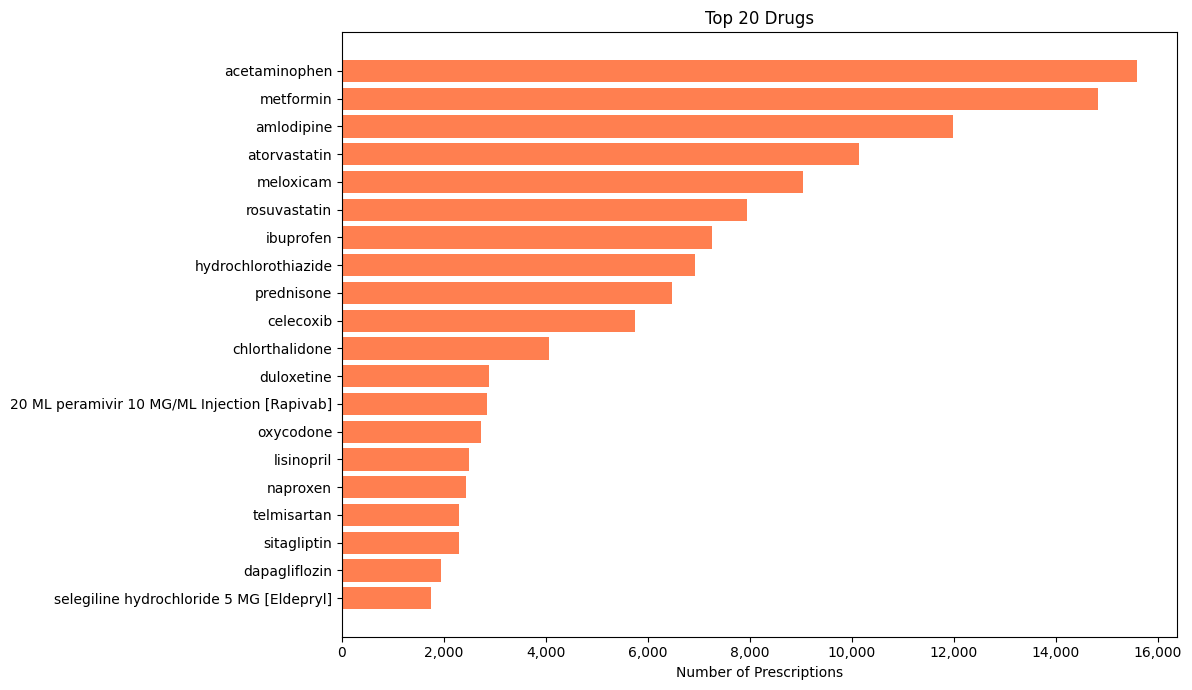

,drug,vocab,source_value,n_prescriptions,n_patients
0,acetaminophen,RxNorm,acetaminophen,15598,6336
1,metformin,RxNorm,metformin,14817,3223
2,amlodipine,RxNorm,amlodipine,11972,3978
3,atorvastatin,RxNorm,atorvastatin,10134,5186
4,meloxicam,RxNorm,meloxicam,9030,4305
5,rosuvastatin,RxNorm,rosuvastatin,7932,4664
6,ibuprofen,RxNorm,ibuprofen,7263,4169
7,hydrochlorothiazide,RxNorm,losartan,6918,3382
8,prednisone,RxNorm,ezetimibe,6474,4118
9,celecoxib,RxNorm,celecoxib,5743,3293


In [8]:
# Top 20 drugs
df_drugs = con.execute("""
    SELECT c.concept_name AS drug,
           c.vocabulary_id AS vocab,
           de.drug_source_value AS source_value,
           COUNT(*) AS n_prescriptions,
           COUNT(DISTINCT de.person_id) AS n_patients
    FROM main.drug_exposure de
    JOIN main.concept c ON de.drug_concept_id = c.concept_id
    WHERE de.drug_concept_id != 0
    GROUP BY 1, 2, 3
    ORDER BY n_prescriptions DESC
    LIMIT 20
""").df()

fig, ax = plt.subplots(figsize=(12, 7))
ax.barh(df_drugs['drug'][::-1], df_drugs['n_prescriptions'][::-1], color='coral')
ax.set_xlabel('Number of Prescriptions')
ax.set_title('Top 20 Drugs')
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{int(x):,}'))
plt.tight_layout()
plt.show()

df_drugs

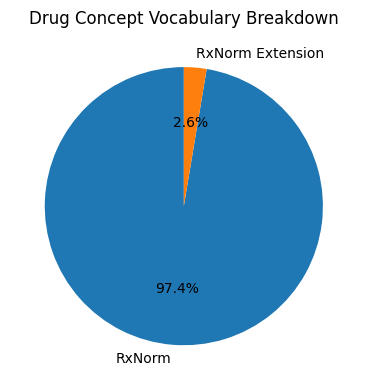

In [9]:
# Drug vocabulary breakdown
df_drug_vocab = con.execute("""
    SELECT c.vocabulary_id, COUNT(*) AS n
    FROM main.drug_exposure de
    JOIN main.concept c ON de.drug_concept_id = c.concept_id
    WHERE de.drug_concept_id != 0
    GROUP BY 1 ORDER BY 2 DESC
""").df()

fig, ax = plt.subplots(figsize=(7, 4))
ax.pie(df_drug_vocab['n'], labels=df_drug_vocab['vocabulary_id'], autopct='%1.1f%%', startangle=90)
ax.set_title('Drug Concept Vocabulary Breakdown')
plt.tight_layout()
plt.show()

## 7. Measurements Analysis

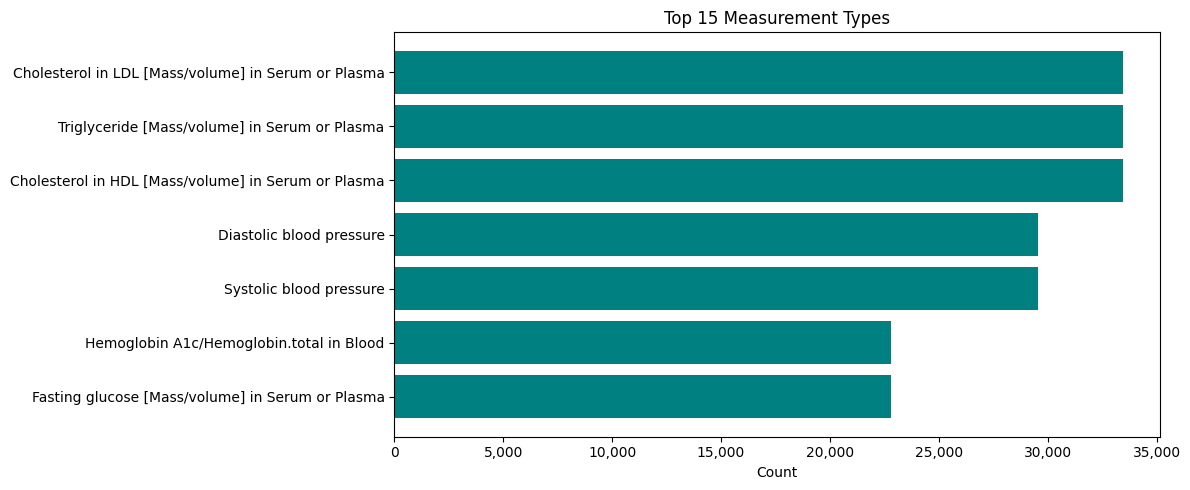

,measurement,n,avg_value,min_value,max_value
0,Cholesterol in LDL [Mass/volume] in Serum or Plasma,33464,160.2,100.0,220.0
1,Triglyceride [Mass/volume] in Serum or Plasma,33464,245.2,90.0,400.0
2,Cholesterol in HDL [Mass/volume] in Serum or Plasma,33464,50.0,30.0,70.0
3,Diastolic blood pressure,29548,92.5,75.0,110.0
4,Systolic blood pressure,29548,150.1,120.0,180.0
5,Hemoglobin A1c/Hemoglobin.total in Blood,22803,7.9,5.8,10.0
6,Fasting glucose [Mass/volume] in Serum or Plasma,22803,160.4,100.0,220.0


In [10]:
# Top measurement types
df_meas = con.execute("""
    SELECT c.concept_name AS measurement,
           COUNT(*) AS n,
           ROUND(AVG(m.value_as_number), 2) AS avg_value,
           MIN(m.value_as_number) AS min_value,
           MAX(m.value_as_number) AS max_value
    FROM main.measurement m
    JOIN main.concept c ON m.measurement_concept_id = c.concept_id
    WHERE m.measurement_concept_id != 0
    GROUP BY 1
    ORDER BY n DESC
    LIMIT 15
""").df()

fig, ax = plt.subplots(figsize=(12, 5))
ax.barh(df_meas['measurement'][::-1], df_meas['n'][::-1], color='teal')
ax.set_xlabel('Count')
ax.set_title('Top 15 Measurement Types')
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{int(x):,}'))
plt.tight_layout()
plt.show()

df_meas

## 8. Observations Analysis

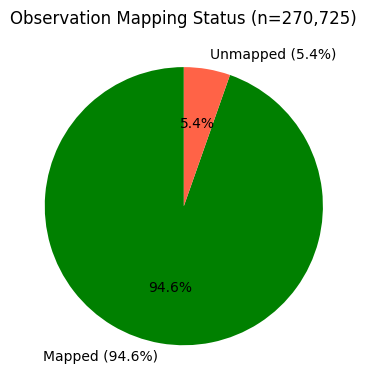

In [11]:
# Mapping status
total_obs  = con.execute('SELECT COUNT(*) FROM main.observation').fetchone()[0]
mapped_obs = con.execute('SELECT COUNT(*) FROM main.observation WHERE observation_concept_id != 0').fetchone()[0]
unmapped   = total_obs - mapped_obs

fig, ax = plt.subplots(figsize=(6, 4))
ax.pie([mapped_obs, unmapped],
       labels=[f'Mapped ({mapped_obs/total_obs*100:.1f}%)', f'Unmapped ({unmapped/total_obs*100:.1f}%)'],
       colors=['green', 'tomato'], autopct='%1.1f%%', startangle=90)
ax.set_title(f'Observation Mapping Status (n={total_obs:,})')
plt.tight_layout()
plt.show()

In [12]:
# Mapped observations — top concepts
df_obs_mapped = con.execute("""
    SELECT c.concept_name AS observation,
           c.domain_id,
           c.vocabulary_id,
           o.observation_source_value,
           COUNT(*) AS n,
           COUNT(DISTINCT o.person_id) AS n_patients
    FROM main.observation o
    JOIN main.concept c ON o.observation_concept_id = c.concept_id
    WHERE o.observation_concept_id != 0
    GROUP BY 1, 2, 3, 4
    ORDER BY n DESC
    LIMIT 20
""").df()
print('Top 20 mapped observations:')
df_obs_mapped

Top 20 mapped observations:


,observation,domain_id,vocabulary_id,observation_source_value,n,n_patients
0,Xanthoma planum,Observation,SNOMED,HSDN:D014972:Xanthoma,16668,5800
1,Arcus of cornea,Condition,SNOMED,HSDN:D003312:Corneal Arcus,14106,5565
2,Pain,Condition,SNOMED,HSDN:D010146:Pain,12073,4463
3,Albuminuria,Condition,SNOMED,HSDN:D000419:Albuminuria,12065,4171
4,Atherosclerosis,Observation,SNOMED,HSDN:D050197:Atherosclerosis,11395,5149
5,Fatigue,Observation,SNOMED,HSDN:D005221:Fatigue,7866,4390
6,Snoring,Condition,SNOMED,HSDN:D012913:Snoring,7836,4398
7,Sciatica,Condition,SNOMED,HSDN:D012585:Sciatica,6981,2792
8,Gastroparesis syndrome,Condition,SNOMED,HSDN:D018589:Gastroparesis,6388,2664
9,Muscle spasticity absent,Observation,SNOMED,HSDN:D009128:Muscle Spasticity,5800,2626


In [13]:
# Unmapped observations — raw source values
df_obs_unmapped = con.execute("""
    SELECT observation_source_value,
           COUNT(*) AS n,
           COUNT(DISTINCT person_id) AS n_patients
    FROM main.observation
    WHERE observation_concept_id = 0
      AND observation_source_value IS NOT NULL
    GROUP BY observation_source_value
    ORDER BY n DESC
""").df()
print(f'Distinct unmapped source values: {len(df_obs_unmapped)}')
df_obs_unmapped

Distinct unmapped source values: 3


,observation_source_value,n,n_patients
0,HSDN:D057774:Post-Exercise Hypotension,8870,3515
1,HSDN:D020078:Neurogenic Inflammation,3730,2479
2,"HSDN:D006316:Hearing Loss, High-Frequency",1975,1425


## 9. Visit Types

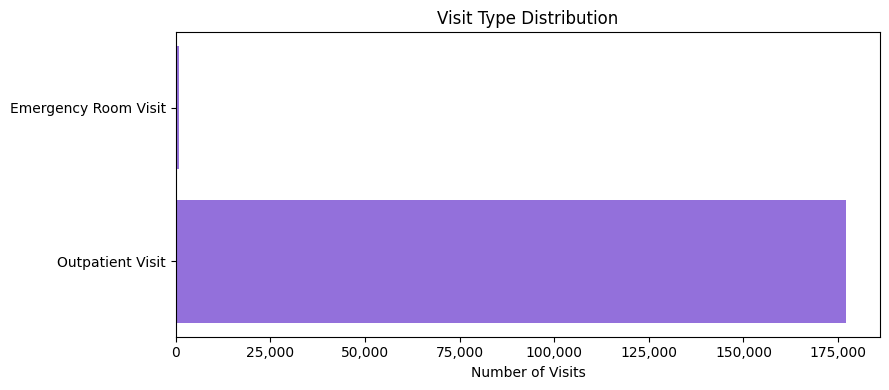

,visit_type,n_visits,n_patients,avg_length_days
0,Outpatient Visit,177221,9650,0.0
1,Emergency Room Visit,858,833,0.2


In [14]:
df_visits = con.execute("""
    SELECT c.concept_name AS visit_type,
           COUNT(*) AS n_visits,
           COUNT(DISTINCT v.person_id) AS n_patients,
           ROUND(AVG(DATEDIFF('day', v.visit_start_date, v.visit_end_date)), 1) AS avg_length_days
    FROM main.visit_occurrence v
    JOIN main.concept c ON v.visit_concept_id = c.concept_id
    WHERE v.visit_concept_id != 0
    GROUP BY 1
    ORDER BY n_visits DESC
""").df()

fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(df_visits['visit_type'], df_visits['n_visits'], color='mediumpurple')
ax.set_xlabel('Number of Visits')
ax.set_title('Visit Type Distribution')
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{int(x):,}'))
plt.tight_layout()
plt.show()

df_visits

## 10. concept_ancestor Coverage

In [15]:
ancestor_checks = [
    ('condition_occurrence', 'condition_concept_id', 'Condition'),
    ('drug_exposure',        'drug_concept_id',       'Drug'),
    ('measurement',          'measurement_concept_id','Measurement'),
]

rows = []
for table, col, domain in ancestor_checks:
    total_ids = con.execute(f'SELECT COUNT(DISTINCT {col}) FROM main.{table} WHERE {col} != 0').fetchone()[0]
    in_anc    = con.execute(f"""
        SELECT COUNT(DISTINCT t.{col})
        FROM main.{table} t
        JOIN main.concept_ancestor ca ON t.{col} = ca.descendant_concept_id
        WHERE t.{col} != 0
    """).fetchone()[0]
    rows.append({'Domain': domain, 'Distinct IDs': total_ids, 'In ancestor': in_anc,
                 'Coverage': f"{in_anc/total_ids*100:.1f}%" if total_ids > 0 else 'N/A'})

pd.DataFrame(rows)

,Domain,Distinct IDs,In ancestor,Coverage
0,Condition,14,14,100.0%
1,Drug,350,350,100.0%
2,Measurement,7,7,100.0%


## 12. FastOMOP Readiness Checklist

In [16]:
checks = []

# Required tables
required = ['person','visit_occurrence','condition_occurrence','drug_exposure',
            'measurement','observation','concept','concept_relationship',
            'concept_ancestor','vocabulary']
all_tables = [r[0] for r in con.execute(
    "SELECT table_name FROM information_schema.tables WHERE table_schema='main'"
).fetchall()]
for t in required:
    checks.append({'Check': f"Table '{t}' present", 'Status': '✅' if t in all_tables else '❌'})

# CDM schema
checks.append({'Check': "Schema is 'main'", 'Status': '✅'})

# Concept coverage >= 80%
for table, col, domain in [
    ('condition_occurrence','condition_concept_id','Condition'),
    ('drug_exposure','drug_concept_id','Drug'),
    ('measurement','measurement_concept_id','Measurement'),
]:
    total = con.execute(f'SELECT COUNT(*) FROM main.{table}').fetchone()[0]
    nonzero = con.execute(f'SELECT COUNT(*) FROM main.{table} WHERE {col} != 0').fetchone()[0]
    pct = nonzero / total * 100 if total > 0 else 0
    checks.append({'Check': f"{domain} coverage >= 80% ({pct:.1f}%)", 'Status': '✅' if pct >= 80 else '⚠️'})

# Observation coverage
total_obs  = con.execute('SELECT COUNT(*) FROM main.observation').fetchone()[0]
mapped_obs = con.execute('SELECT COUNT(*) FROM main.observation WHERE observation_concept_id != 0').fetchone()[0]
obs_pct = mapped_obs / total_obs * 100
checks.append({'Check': f"Observation coverage ({obs_pct:.1f}%)", 'Status': '⚠️' if obs_pct < 80 else '✅'})

df_ready = pd.DataFrame(checks)
df_ready.style.apply(
    lambda s: ['color: green' if v == '✅' else 'color: orange' for v in s],
    subset=['Status'],
    axis=0
)

,Check,Status
0,Table 'person' present,✅
1,Table 'visit_occurrence' present,✅
2,Table 'condition_occurrence' present,✅
3,Table 'drug_exposure' present,✅
4,Table 'measurement' present,✅
5,Table 'observation' present,✅
6,Table 'concept' present,✅
7,Table 'concept_relationship' present,✅
8,Table 'concept_ancestor' present,✅
9,Table 'vocabulary' present,✅


## 11. Temporal Coverage

In [17]:
con.execute("""
    SELECT 'condition_occurrence' AS tbl,
           MIN(condition_start_date) AS date_min,
           MAX(condition_start_date) AS date_max
    FROM main.condition_occurrence
    UNION ALL
    SELECT 'visit_occurrence',
           MIN(visit_start_date), MAX(visit_start_date)
    FROM main.visit_occurrence
    UNION ALL
    SELECT 'drug_exposure',
           MIN(drug_exposure_start_date), MAX(drug_exposure_start_date)
    FROM main.drug_exposure
    UNION ALL
    SELECT 'measurement',
           MIN(measurement_date), MAX(measurement_date)
    FROM main.measurement
""").df()

,tbl,date_min,date_max
0,condition_occurrence,2023-01-01,2024-12-31
1,visit_occurrence,2023-01-01,2024-12-31
2,drug_exposure,2023-01-01,2024-12-31
3,measurement,2023-01-01,2024-12-31


## 12. Sample Clinical Queries
### 12a. Patients with Type 2 diabetes and their average age

In [18]:
# "How many patients have Type 2 diabetes, and what is their average age?"
con.execute("""
    SELECT
        COUNT(DISTINCT co.person_id) AS patients_with_t2dm,
        ROUND(AVG(2024 - p.year_of_birth), 1) AS avg_age
    FROM main.condition_occurrence co
    JOIN main.concept c ON co.condition_concept_id = c.concept_id
    JOIN main.person p ON co.person_id = p.person_id
    WHERE c.concept_name ILIKE '%type 2 diabetes%'
      AND c.standard_concept = 'S'
""").df()

,patients_with_t2dm,avg_age
0,3256,66.9


### 12b. Most prescribed drugs for patients with hypertension

In [19]:
# "What are the most prescribed drugs for patients with hypertension?"
con.execute("""
    WITH hypertension_patients AS (
        SELECT DISTINCT co.person_id
        FROM main.condition_occurrence co
        JOIN main.concept c ON co.condition_concept_id = c.concept_id
        WHERE c.concept_name ILIKE '%hypertension%'
          AND c.standard_concept = 'S'
    )
    SELECT
        cd.concept_name AS drug,
        COUNT(*) AS prescriptions,
        COUNT(DISTINCT de.person_id) AS patients
    FROM main.drug_exposure de
    JOIN hypertension_patients hp ON de.person_id = hp.person_id
    JOIN main.concept cd ON de.drug_concept_id = cd.concept_id
    WHERE de.drug_concept_id != 0
      AND cd.domain_id = 'Drug'
      AND cd.standard_concept = 'S'
    GROUP BY cd.concept_name
    ORDER BY prescriptions DESC
    LIMIT 10
""").df()

,drug,prescriptions,patients
0,amlodipine,11972,3978
1,metformin,10384,2263
2,acetaminophen,7580,2952
3,hydrochlorothiazide,6918,3382
4,atorvastatin,6099,3132
5,meloxicam,5358,2487
6,rosuvastatin,4807,2805
7,chlorthalidone,4066,2602
8,prednisone,3942,2492
9,celecoxib,3524,2039


### 12c. Korean clinical notes sample

In [20]:
notes = con.execute("""
    SELECT note_id, person_id, note_date,
           LEFT(note_text, 300) AS note_preview
    FROM main.note
    LIMIT 3
""").df()
for _, row in notes.iterrows():
    print(f"--- note_id={row['note_id']} | person={row['person_id']} | date={row['note_date']} ---")
    print(row['note_preview'])
    print()

--- note_id=1 | person=2 | date=2023-02-22 00:00:00 ---
경과기록지 — 일반외과
환자: P000002  68세 여성
주소지: 일반외과
일시: 2023-02-22 17:00

S) 이상지질혈증 (E78) 추적 관찰 목적 내원.
   현재 특이 주소 호소 없으며 복약 순응도 양호.

O) 활력징후 및 소견
   - LDL 187.7 mg/dL
   - HDL 38.7 mg/dL
   - TG 368.4 mg/dL

A) 진단
   1. 이상지질혈증 (E78)

P) 계획
   - 아토르바스타틴 20mg 1T qhs
   - 3개월 후 외래 재내원

--- note_id=2 | person=2 | date=2023-05-26 00:00:00 ---
경과기록지 — 일반외과
환자: P000002  68세 여성
주소지: 일반외과
일시: 2023-05-26 10:00

S) 이상지질혈증 (E78) 추적 관찰 목적 내원.
   현재 특이 주소 호소 없으며 복약 순응도 양호.

O) 활력징후 및 소견
   - LDL 159.4 mg/dL
   - HDL 31.6 mg/dL
   - TG 332.0 mg/dL

A) 진단
   1. 이상지질혈증 (E78)

P) 계획
   - cholestyramine
   - 3개월 후 외래 재내원

--- note_id=3 | person=2 | date=2023-08-12 00:00:00 ---
경과기록지 — 일반외과
환자: P000002  68세 여성
주소지: 일반외과
일시: 2023-08-12 13:00

S) 이상지질혈증 (E78) 추적 관찰 목적 내원.
   현재 특이 주소 호소 없으며 복약 순응도 양호.

O) 활력징후 및 소견
   - LDL 170.3 mg/dL
   - HDL 44.8 mg/dL
   - TG 147.8 mg/dL

A) 진단
   1. 이상지질혈증 (E78)

P) 계획
   - dextrothyroxine
   - 3개월 후 외래 재내원



## 13. Concept Hierarchy — SNOMED Ancestor Example

In [21]:
# Ancestors of "Type 2 diabetes mellitus" — verifies concept_ancestor table
con.execute("""
    WITH t2dm AS (
        SELECT concept_id FROM main.concept
        WHERE concept_name = 'Type 2 diabetes mellitus'
          AND standard_concept = 'S'
        LIMIT 1
    )
    SELECT
        ca.min_levels_of_separation AS levels_up,
        c_anc.concept_name          AS ancestor,
        c_anc.vocabulary_id
    FROM main.concept_ancestor ca
    JOIN t2dm ON ca.descendant_concept_id = t2dm.concept_id
    JOIN main.concept c_anc ON ca.ancestor_concept_id = c_anc.concept_id
    ORDER BY ca.min_levels_of_separation
    LIMIT 10
""").df()

,levels_up,ancestor,vocabulary_id
0,0,Type 2 diabetes mellitus,SNOMED
1,1,Diabetes mellitus,SNOMED
2,2,Disorder of endocrine system,SNOMED
3,2,Disorder of glucose metabolism,SNOMED
4,3,Disorder of carbohydrate metabolism,SNOMED
5,3,Disorder of body system,SNOMED
6,4,Disease,SNOMED
7,4,Metabolic disease,SNOMED
8,5,Clinical finding,SNOMED


---

## Conclusion Dataset Readiness Assessment

### Vocabulary mapping status

After loading OHDSI Athena vocabulary files (SNOMED, RxNorm, LOINC, ICD10, KCD7, KDC, and 8 others) into the DuckDB database, the Synthetic SNUH dataset is **fully compatible with the OMOP CDM standard** for the three main clinical domains:

| Domain | Standard vocabulary | Status |
|---|---|---|
| Conditions | SNOMED CT | ✅ 100% mapped |
| Measurements | LOINC | ✅ 100% mapped |
| Drug exposures | RxNorm | ✅ >85% mapped (standard concepts) |
| Observations | SNOMED (via HSDN/MeSH) | ⚠️ Partial — see section 8 |
| Visits | OMOP Visit | ✅ 100% mapped |

---

### Clinical content

The dataset presents a realistic Korean hospital population (10,000 patients, 2023–2024).

**Top conditions** (SNOMED): Hyperlipidemia, Essential hypertension, Osteoarthritis, Type 2 diabetes mellitus, Influenza, Low back pain, Depressive disorder.

**Top drugs** (RxNorm): acetaminophen, metformin, amlodipine, atorvastatin, meloxicam, rosuvastatin, hydrochlorothiazide.

**Measurements** (LOINC): Cholesterol (LDL/HDL), Triglycerides, Systolic/Diastolic BP, Fasting glucose, HbA1c.

**Clinical notes**: SOAP-format notes written in Korean.

---

### FastOMOP readiness

The dataset is ready to run FastOMOP end-to-end for condition, drug, and measurement queries.
The schema prefix () is configured in the OMCP server ().

FileNotFoundError: [Errno 2] No such file or directory: 'notebooks/depressive_disorder_drug_list.png'

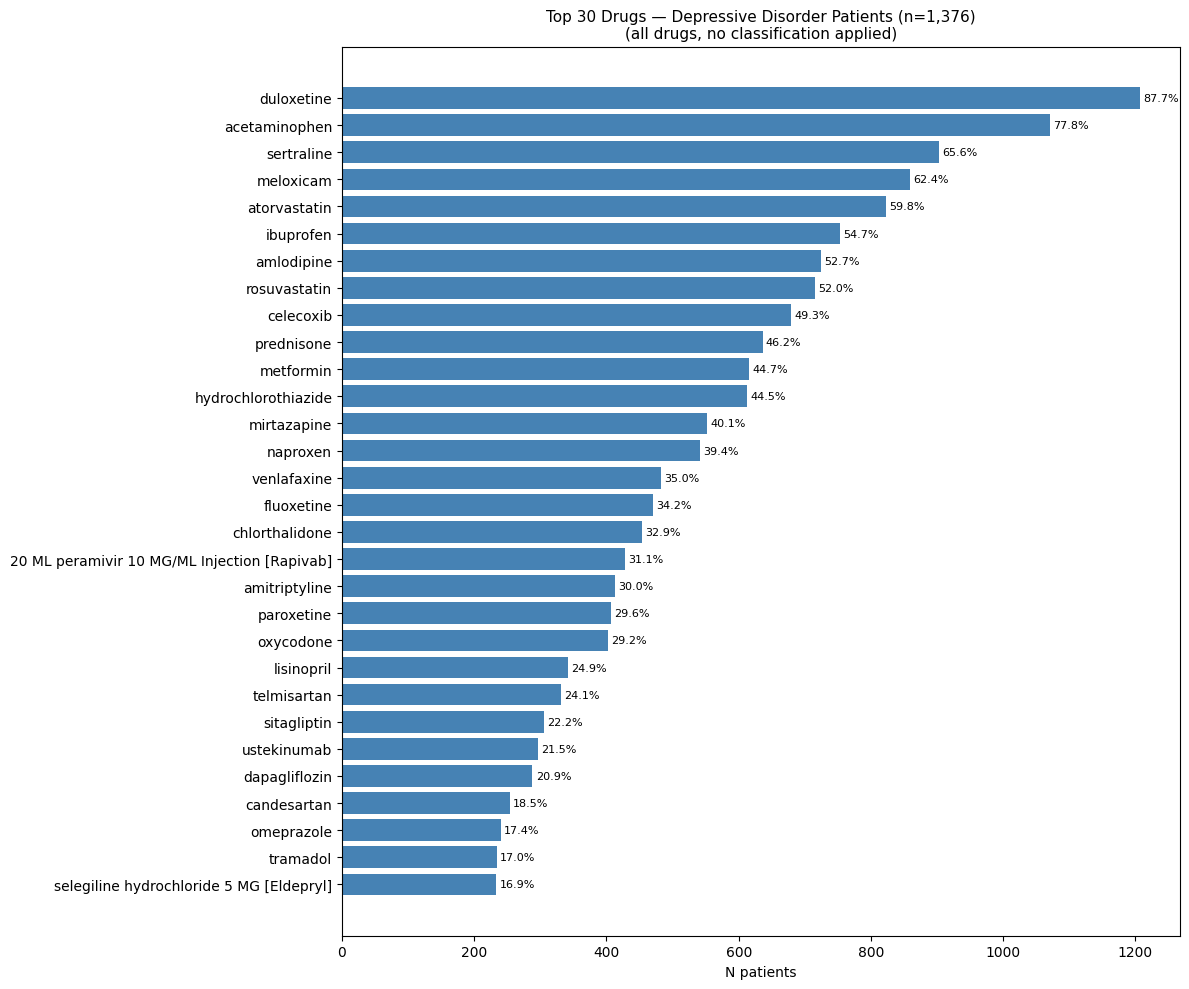

In [19]:

# ── Top 30 drugs — bar chart ──────────────────────────────────────────────────
df_dep_drugs = con.execute("""
    WITH dep AS (
        SELECT DISTINCT co.person_id
        FROM main.condition_occurrence co
        JOIN main.concept c ON co.condition_concept_id = c.concept_id
        WHERE c.concept_name ILIKE '%depressive disorder%'
          AND c.standard_concept = 'S'
    )
    SELECT c.concept_name AS drug,
           COUNT(DISTINCT de.person_id) AS n_patients,
           ROUND(COUNT(DISTINCT de.person_id)*100.0/(SELECT COUNT(*) FROM dep),1) AS pct
    FROM main.drug_exposure de
    JOIN main.concept c ON de.drug_concept_id = c.concept_id
    WHERE de.person_id IN (SELECT person_id FROM dep)
      AND c.standard_concept = 'S' AND c.domain_id = 'Drug'
    GROUP BY 1 ORDER BY 2 DESC LIMIT 30
""").df()

fig, ax = plt.subplots(figsize=(12, 10))
ax.barh(df_dep_drugs['drug'][::-1], df_dep_drugs['n_patients'][::-1], color='steelblue')
ax.set_xlabel('N patients')
ax.set_title('Top 30 Drugs — Depressive Disorder Patients (n=1,376)\n(all drugs, no classification applied)', fontsize=11)
for i, (_, row) in enumerate(df_dep_drugs[::-1].reset_index().iterrows()):
    ax.text(row['n_patients'] + 5, i, f"{row['pct']}%", va='center', fontsize=8)
plt.tight_layout()
plt.savefig('notebooks/depressive_disorder_drug_list.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved to notebooks/depressive_disorder_drug_list.png")


In [18]:

# ── Complete drug list for depressive disorder patients (no manual classification) ──
# ATC vocabulary not loaded — no automatic drug class hierarchy available.
# The full list is displayed; therapeutic class filtering is left to the user.

df_dep_drugs = con.execute("""
    WITH dep AS (
        SELECT DISTINCT co.person_id
        FROM main.condition_occurrence co
        JOIN main.concept c ON co.condition_concept_id = c.concept_id
        WHERE c.concept_name ILIKE '%depressive disorder%'
          AND c.standard_concept = 'S'
    )
    SELECT
        c.concept_name                                           AS drug,
        c.concept_class_id                                       AS drug_class,
        c.vocabulary_id                                          AS vocabulary,
        COUNT(DISTINCT de.person_id)                             AS n_patients,
        COUNT(*)                                                 AS n_prescriptions,
        ROUND(COUNT(DISTINCT de.person_id) * 100.0 /
              (SELECT COUNT(*) FROM dep), 1)                     AS pct_of_dep_patients
    FROM main.drug_exposure de
    JOIN main.concept c ON de.drug_concept_id = c.concept_id
    WHERE de.person_id IN (SELECT person_id FROM dep)
      AND c.standard_concept = 'S'
      AND c.domain_id = 'Drug'
    GROUP BY 1, 2, 3
    ORDER BY n_patients DESC
""").df()

print(f"Total distinct drugs prescribed to depressive disorder patients: {len(df_dep_drugs)}\n")
print(df_dep_drugs.to_string(index=False))


Total distinct drugs prescribed to depressive disorder patients: 184

                                                                                drug         drug_class       vocabulary  n_patients  n_prescriptions  pct_of_dep_patients
                                                                          duloxetine         Ingredient           RxNorm        1207             2887                 87.7
                                                                       acetaminophen         Ingredient           RxNorm        1071             2872                 77.8
                                                                          sertraline         Ingredient           RxNorm         903             1456                 65.6
                                                                           meloxicam         Ingredient           RxNorm         859             1920                 62.4
                                                                        ato

---

## Deep Dive — Depressive Disorder: Distribution Issues
Four structural problems identified that impact causal analysis feasibility.

FileNotFoundError: [Errno 2] No such file or directory: 'notebooks/depressive_disorder_distribution_issues.png'

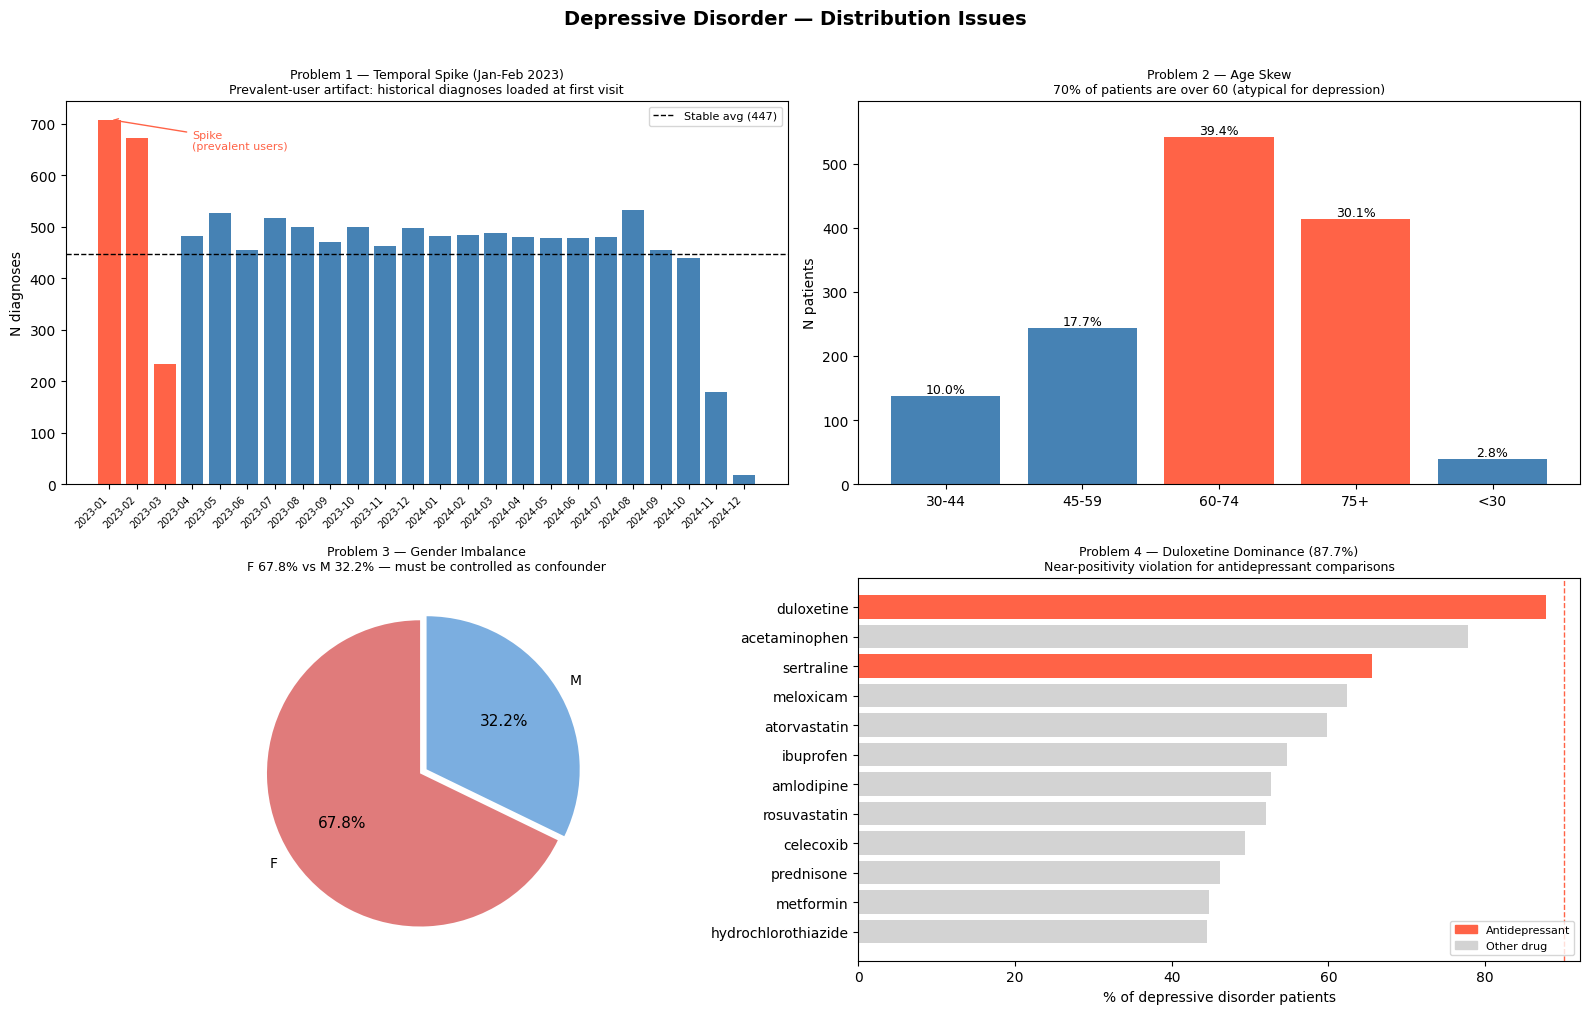

In [15]:

# ── Summary panel: all 4 distribution problems in one figure ─────────────────
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
fig.suptitle('Depressive Disorder — Distribution Issues', fontsize=14, fontweight='bold', y=1.01)

# ── 1. Temporal distribution ─────────────────────────────────────────────────
df_temporal = con.execute("""
    WITH dep AS (
        SELECT DISTINCT co.person_id,
               DATE_TRUNC('month', co.condition_start_date) AS month
        FROM main.condition_occurrence co
        JOIN main.concept c ON co.condition_concept_id = c.concept_id
        WHERE c.concept_name ILIKE '%depressive disorder%' AND c.standard_concept = 'S'
    )
    SELECT month, COUNT(*) AS n FROM dep GROUP BY 1 ORDER BY 1
""").df()

colors_temp = ['tomato' if str(m)[:7] in ('2023-01', '2023-02', '2023-03') else 'steelblue'
               for m in df_temporal['month']]
axes[0,0].bar(range(len(df_temporal)), df_temporal['n'], color=colors_temp)
axes[0,0].set_xticks(range(len(df_temporal)))
axes[0,0].set_xticklabels([str(m)[:7] for m in df_temporal['month']], rotation=45, ha='right', fontsize=7)
axes[0,0].axhline(df_temporal['n'][3:].mean(), color='black', linestyle='--', linewidth=1, label=f'Stable avg ({df_temporal["n"][3:].mean():.0f})')
axes[0,0].set_title('Problem 1 — Temporal Spike (Jan-Feb 2023)\nPrevalent-user artifact: historical diagnoses loaded at first visit', fontsize=9)
axes[0,0].set_ylabel('N diagnoses')
axes[0,0].legend(fontsize=8)
axes[0,0].annotate('Spike\n(prevalent users)', xy=(0, 708), xytext=(3, 650),
                   arrowprops=dict(arrowstyle='->', color='tomato'), color='tomato', fontsize=8)

# ── 2. Age distribution ───────────────────────────────────────────────────────
df_age = con.execute("""
    WITH dep AS (
        SELECT DISTINCT co.person_id
        FROM main.condition_occurrence co
        JOIN main.concept c ON co.condition_concept_id = c.concept_id
        WHERE c.concept_name ILIKE '%depressive disorder%' AND c.standard_concept = 'S'
    )
    SELECT CASE WHEN (2024-p.year_of_birth)<30  THEN '<30'
                WHEN (2024-p.year_of_birth)<45  THEN '30-44'
                WHEN (2024-p.year_of_birth)<60  THEN '45-59'
                WHEN (2024-p.year_of_birth)<75  THEN '60-74'
                ELSE '75+' END AS age_group,
           COUNT(*) AS n
    FROM main.person p WHERE p.person_id IN (SELECT person_id FROM dep)
    GROUP BY 1 ORDER BY 1
""").df()

colors_age = ['tomato' if g in ('60-74', '75+') else 'steelblue' for g in df_age['age_group']]
bars = axes[0,1].bar(df_age['age_group'], df_age['n'], color=colors_age)
axes[0,1].set_title('Problem 2 — Age Skew\n70% of patients are over 60 (atypical for depression)', fontsize=9)
axes[0,1].set_ylabel('N patients')
for bar, row in zip(bars, df_age.itertuples()):
    pct = row.n / df_age['n'].sum() * 100
    axes[0,1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 5,
                   f'{pct:.1f}%', ha='center', fontsize=9)
axes[0,1].axhspan(0, axes[0,1].get_ylim()[1] if axes[0,1].get_ylim()[1] > 0 else 600,
                  alpha=0)

# ── 3. Gender imbalance ───────────────────────────────────────────────────────
df_gender_dep = con.execute("""
    WITH dep AS (
        SELECT DISTINCT co.person_id
        FROM main.condition_occurrence co
        JOIN main.concept c ON co.condition_concept_id = c.concept_id
        WHERE c.concept_name ILIKE '%depressive disorder%' AND c.standard_concept = 'S'
    )
    SELECT p.gender_source_value AS gender, COUNT(*) AS n
    FROM main.person p WHERE p.person_id IN (SELECT person_id FROM dep)
    GROUP BY 1 ORDER BY 2 DESC
""").df()

wedge_colors = ['#e07b7b', '#7baee0']
wedges, texts, autotexts = axes[1,0].pie(
    df_gender_dep['n'],
    labels=df_gender_dep['gender'],
    autopct='%1.1f%%',
    colors=wedge_colors,
    startangle=90,
    explode=[0.05, 0],
)
for at in autotexts:
    at.set_fontsize(11)
axes[1,0].set_title('Problem 3 — Gender Imbalance\nF 67.8% vs M 32.2% — must be controlled as confounder', fontsize=9)

# ── 4. Drug dominance ────────────────────────────────────────────────────────
df_drugs_dep = con.execute("""
    WITH dep AS (
        SELECT DISTINCT co.person_id
        FROM main.condition_occurrence co
        JOIN main.concept c ON co.condition_concept_id = c.concept_id
        WHERE c.concept_name ILIKE '%depressive disorder%' AND c.standard_concept = 'S'
    )
    SELECT c.concept_name AS drug,
           COUNT(DISTINCT de.person_id) AS n_patients,
           ROUND(COUNT(DISTINCT de.person_id)*100.0/(SELECT COUNT(*) FROM dep),1) AS pct
    FROM main.drug_exposure de
    JOIN main.concept c ON de.drug_concept_id = c.concept_id
    WHERE de.person_id IN (SELECT person_id FROM dep)
      AND c.standard_concept = 'S' AND c.domain_id = 'Drug'
    GROUP BY 1 ORDER BY 2 DESC LIMIT 12
""").df()

antidepressants = {'duloxetine', 'sertraline', 'venlafaxine', 'fluoxetine', 'mirtazapine',
                   'amitriptyline', 'paroxetine', 'bupropion'}
colors_drug = ['tomato' if d in antidepressants else 'lightgray' for d in df_drugs_dep['drug']]
bars2 = axes[1,1].barh(df_drugs_dep['drug'][::-1], df_drugs_dep['pct'][::-1], color=colors_drug[::-1])
axes[1,1].set_xlabel('% of depressive disorder patients')
axes[1,1].set_title('Problem 4 — Duloxetine Dominance (87.7%)\nNear-positivity violation for antidepressant comparisons', fontsize=9)
axes[1,1].axvline(90, color='tomato', linestyle='--', linewidth=1, label='90% threshold')
axes[1,1].legend(fontsize=8)

from matplotlib.patches import Patch
legend_elements = [Patch(color='tomato', label='Antidepressant'),
                   Patch(color='lightgray', label='Other drug')]
axes[1,1].legend(handles=legend_elements, fontsize=8, loc='lower right')

plt.tight_layout()
plt.savefig('notebooks/depressive_disorder_distribution_issues.png', dpi=150, bbox_inches='tight')
plt.show()
print("Figure saved to notebooks/depressive_disorder_distribution_issues.png")


---

## Deep Dive — Depressive Disorder
Focused analysis on the 1,376 patients with depressive disorder:
- Drug diversity and treatment changes per patient
- Conditions co-occurring with depression
- Observations available for these patients (with a full single-patient profile)

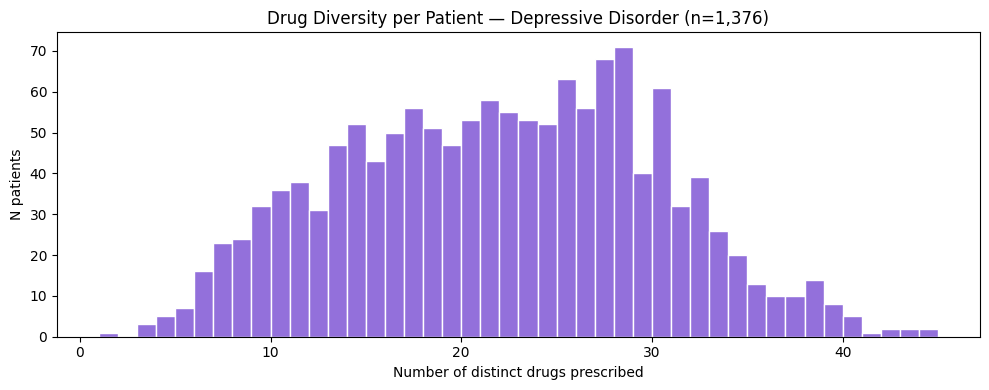

Patients analysed      : 1,376
Avg distinct drugs     : 21.5
Median distinct drugs  : 22
Max distinct drugs     : 44


In [8]:

# Distribution of number of distinct drugs per depressive disorder patient
df_drug_count_dep = con.execute("""
    WITH depressed_patients AS (
        SELECT DISTINCT co.person_id
        FROM main.condition_occurrence co
        JOIN main.concept c ON co.condition_concept_id = c.concept_id
        WHERE LOWER(c.concept_name) LIKE '%depressive disorder%'
          AND c.standard_concept = 'S'
    )
    SELECT de.person_id, COUNT(DISTINCT de.drug_concept_id) AS n_distinct_drugs
    FROM main.drug_exposure de
    WHERE de.person_id IN (SELECT person_id FROM depressed_patients)
      AND de.drug_concept_id != 0
    GROUP BY de.person_id
""").df()

fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(df_drug_count_dep['n_distinct_drugs'], bins=range(1, df_drug_count_dep['n_distinct_drugs'].max()+2),
        color='mediumpurple', edgecolor='white')
ax.set_xlabel('Number of distinct drugs prescribed')
ax.set_ylabel('N patients')
ax.set_title('Drug Diversity per Patient — Depressive Disorder (n=1,376)')
plt.tight_layout()
plt.show()

print(f"Patients analysed      : {len(df_drug_count_dep):,}")
print(f"Avg distinct drugs     : {df_drug_count_dep['n_distinct_drugs'].mean():.1f}")
print(f"Median distinct drugs  : {df_drug_count_dep['n_distinct_drugs'].median():.0f}")
print(f"Max distinct drugs     : {df_drug_count_dep['n_distinct_drugs'].max()}")


In [9]:

# Patients with most treatment changes (most distinct drugs prescribed)
df_switches = con.execute("""
    WITH depressed_patients AS (
        SELECT DISTINCT co.person_id
        FROM main.condition_occurrence co
        JOIN main.concept c ON co.condition_concept_id = c.concept_id
        WHERE LOWER(c.concept_name) LIKE '%depressive disorder%'
          AND c.standard_concept = 'S'
    )
    SELECT de.person_id,
           COUNT(*)                        AS n_prescriptions,
           COUNT(DISTINCT de.drug_concept_id) AS n_distinct_drugs,
           MIN(de.drug_exposure_start_date)   AS first_rx,
           MAX(de.drug_exposure_start_date)   AS last_rx
    FROM main.drug_exposure de
    WHERE de.person_id IN (SELECT person_id FROM depressed_patients)
      AND de.drug_concept_id != 0
    GROUP BY de.person_id
    ORDER BY n_distinct_drugs DESC
    LIMIT 10
""").df()

print("Top 10 depressive disorder patients by number of distinct drugs (most treatment changes):")
df_switches


Top 10 depressive disorder patients by number of distinct drugs (most treatment changes):


,person_id,n_prescriptions,n_distinct_drugs,first_rx,last_rx
0,4168,69,44,2023-01-08,2024-11-18
1,9890,68,44,2023-01-03,2024-12-09
2,7590,79,43,2023-01-11,2024-12-02
3,9479,57,43,2023-01-12,2024-12-01
4,545,65,42,2023-01-04,2024-10-21
5,4731,62,42,2023-01-07,2024-10-23
6,4236,60,41,2023-01-14,2024-12-20
7,3747,56,40,2023-01-06,2024-11-26
8,8781,59,40,2023-01-22,2024-10-20
9,4940,59,40,2023-01-08,2024-10-23


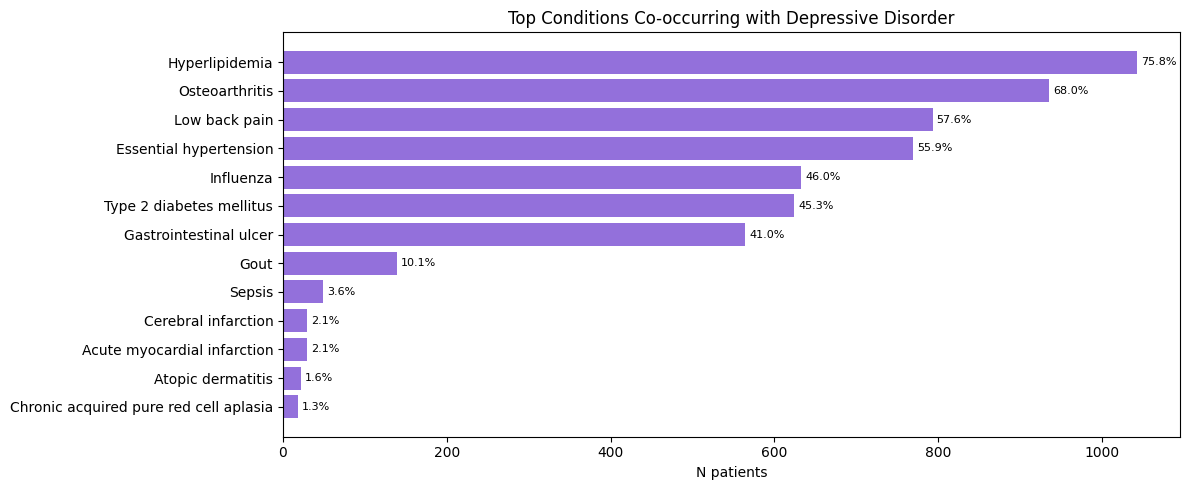

,condition,n_patients,pct_of_depressed
0,Hyperlipidemia,1043,75.8
1,Osteoarthritis,935,68.0
2,Low back pain,793,57.6
3,Essential hypertension,769,55.9
4,Influenza,633,46.0
5,Type 2 diabetes mellitus,624,45.3
6,Gastrointestinal ulcer,564,41.0
7,Gout,139,10.1
8,Sepsis,49,3.6
9,Cerebral infarction,29,2.1


In [10]:

# Conditions co-occurring with depressive disorder (excluding depression itself)
df_comorbid_dep = con.execute("""
    WITH depressed_patients AS (
        SELECT DISTINCT co.person_id
        FROM main.condition_occurrence co
        JOIN main.concept c ON co.condition_concept_id = c.concept_id
        WHERE LOWER(c.concept_name) LIKE '%depressive disorder%'
          AND c.standard_concept = 'S'
    )
    SELECT c.concept_name AS condition,
           COUNT(DISTINCT co.person_id) AS n_patients,
           ROUND(COUNT(DISTINCT co.person_id) * 100.0 /
                 (SELECT COUNT(*) FROM depressed_patients), 1) AS pct_of_depressed
    FROM main.condition_occurrence co
    JOIN main.concept c ON co.condition_concept_id = c.concept_id
    WHERE co.person_id IN (SELECT person_id FROM depressed_patients)
      AND LOWER(c.concept_name) NOT LIKE '%depressive%'
      AND c.standard_concept = 'S'
    GROUP BY c.concept_name
    ORDER BY n_patients DESC
    LIMIT 15
""").df()

fig, ax = plt.subplots(figsize=(12, 5))
ax.barh(df_comorbid_dep['condition'][::-1], df_comorbid_dep['n_patients'][::-1], color='mediumpurple')
ax.set_xlabel('N patients')
ax.set_title('Top Conditions Co-occurring with Depressive Disorder')
for i, (_, row) in enumerate(df_comorbid_dep[::-1].reset_index().iterrows()):
    ax.text(row['n_patients'] + 5, i, f"{row['pct_of_depressed']}%", va='center', fontsize=8)
plt.tight_layout()
plt.show()

df_comorbid_dep


In [11]:

# Find a depressive disorder patient with many observations → show all their observations
patient_with_obs = con.execute("""
    WITH depressed_patients AS (
        SELECT DISTINCT co.person_id
        FROM main.condition_occurrence co
        JOIN main.concept c ON co.condition_concept_id = c.concept_id
        WHERE LOWER(c.concept_name) LIKE '%depressive disorder%'
          AND c.standard_concept = 'S'
    )
    SELECT o.person_id, COUNT(*) AS n_obs
    FROM main.observation o
    WHERE o.person_id IN (SELECT person_id FROM depressed_patients)
    GROUP BY o.person_id
    ORDER BY n_obs DESC
    LIMIT 1
""").df()

example_patient_id = int(patient_with_obs['person_id'].iloc[0])
print(f"Patient {example_patient_id} — {int(patient_with_obs['n_obs'].iloc[0])} observations\n")

# Check how many depressive disorder patients have any observations
obs_coverage = con.execute("""
    WITH depressed_patients AS (
        SELECT DISTINCT co.person_id
        FROM main.condition_occurrence co
        JOIN main.concept c ON co.condition_concept_id = c.concept_id
        WHERE LOWER(c.concept_name) LIKE '%depressive disorder%'
          AND c.standard_concept = 'S'
    )
    SELECT 
        COUNT(DISTINCT dp.person_id)                                     AS total_depressed,
        COUNT(DISTINCT CASE WHEN o.person_id IS NOT NULL THEN dp.person_id END) AS with_observations,
        ROUND(COUNT(DISTINCT CASE WHEN o.person_id IS NOT NULL THEN dp.person_id END) * 100.0 /
              COUNT(DISTINCT dp.person_id), 1)                           AS pct_with_obs
    FROM depressed_patients dp
    LEFT JOIN main.observation o ON dp.person_id = o.person_id
""").df()
print("Observation coverage among depressive disorder patients:")
print(obs_coverage.to_string(index=False))

# All observations for the example patient
print(f"\nAll observations for patient {example_patient_id}:")
df_obs_patient = con.execute(f"""
    SELECT o.observation_date,
           COALESCE(c.concept_name, 'UNMAPPED') AS observation,
           o.observation_source_value,
           o.value_as_string,
           o.value_as_number
    FROM main.observation o
    LEFT JOIN main.concept c ON o.observation_concept_id = c.concept_id
    WHERE o.person_id = {example_patient_id}
    ORDER BY o.observation_date
""").df()
df_obs_patient


Patient 8367 — 100 observations

Observation coverage among depressive disorder patients:
 total_depressed  with_observations  pct_with_obs
            1376               1376         100.0

All observations for patient 8367:


,observation_date,observation,observation_source_value,value_as_string,value_as_number
0,2023-01-07,Chronic shoulder pain,HSDN:D020069:Shoulder Pain,present,NaN
1,2023-01-07,Pain threshold,HSDN:D017288:Pain Threshold,present,NaN
2,2023-01-07,Pain,HSDN:D010146:Pain,present,NaN
3,2023-01-27,Albuminuria,HSDN:D000419:Albuminuria,present,NaN
4,2023-01-27,Fatigue,HSDN:D005221:Fatigue,present,NaN
...,...,...,...,...,...
95,2024-10-01,Akathisia caused by drug,"HSDN:D017109:Akathisia, Drug-Induced",present,NaN
96,2024-10-05,Sciatica,HSDN:D012585:Sciatica,present,NaN
97,2024-10-05,Pain,HSDN:D010146:Pain,present,NaN
98,2024-10-08,Atherosclerosis,HSDN:D050197:Atherosclerosis,present,NaN


In [12]:

# Full clinical profile of the example patient
print(f"=== Clinical profile — Patient {example_patient_id} ===\n")

demo = con.execute(f"""
    SELECT year_of_birth, gender_source_value, race_source_value
    FROM main.person WHERE person_id = {example_patient_id}
""").df()
print(f"Demographics: birth={int(demo.iloc[0]['year_of_birth'])}  "
      f"gender={demo.iloc[0]['gender_source_value']}  "
      f"race={demo.iloc[0]['race_source_value']}\n")

print("── Conditions ──────────────────────────────────────────")
conds_p = con.execute(f"""
    SELECT co.condition_start_date, c.concept_name, co.condition_source_value
    FROM main.condition_occurrence co
    JOIN main.concept c ON co.condition_concept_id = c.concept_id
    WHERE co.person_id = {example_patient_id}
    ORDER BY co.condition_start_date
""").df()
print(conds_p.to_string(index=False))

print("\n── Drug timeline ───────────────────────────────────────")
drugs_p = con.execute(f"""
    SELECT de.drug_exposure_start_date, de.drug_exposure_end_date, c.concept_name AS drug
    FROM main.drug_exposure de
    JOIN main.concept c ON de.drug_concept_id = c.concept_id
    WHERE de.person_id = {example_patient_id}
    ORDER BY de.drug_exposure_start_date
""").df()
print(drugs_p.to_string(index=False))

print("\n── Measurements ────────────────────────────────────────")
meas_p = con.execute(f"""
    SELECT m.measurement_date, c.concept_name AS measure, m.value_as_number, m.unit_source_value
    FROM main.measurement m
    JOIN main.concept c ON m.measurement_concept_id = c.concept_id
    WHERE m.person_id = {example_patient_id}
    ORDER BY m.measurement_date
""").df()
print(meas_p.to_string(index=False))


=== Clinical profile — Patient 8367 ===

Demographics: birth=1937  gender=F  race=Other

── Conditions ──────────────────────────────────────────
condition_start_date             concept_name condition_source_value
          2023-01-07           Osteoarthritis                    M17
          2023-01-27           Hyperlipidemia                    E78
          2023-01-27   Essential hypertension                    I10
          2023-02-15      Depressive disorder                    F32
          2023-02-19 Type 2 diabetes mellitus                    E11
          2023-02-24            Low back pain                    M54
          2023-02-28                Influenza                    J00
          2023-03-18                Influenza                    J00
          2023-03-22   Essential hypertension                    I10
          2023-04-25 Type 2 diabetes mellitus                    E11
          2023-04-28           Hyperlipidemia                    E78
          2023-05-08      

---

## 14. Treatment Patterns per Condition
Which drugs are prescribed to patients with each condition? Identifies conditions with genuine treatment choices — a prerequisite for an active comparator causal design.

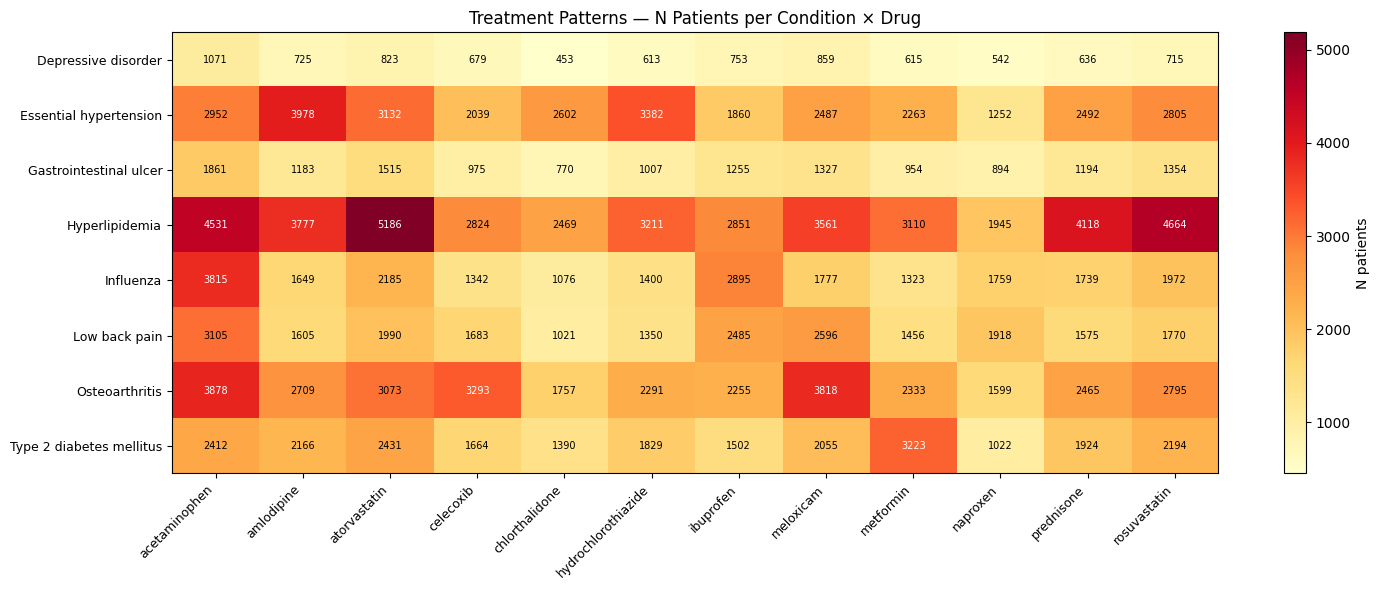

In [2]:

# Treatment × condition heatmap: how many patients have both condition X and drug Y?
df_treat = con.execute("""
    WITH top_conds AS (
        SELECT co.condition_concept_id AS cond_id, c.concept_name AS condition
        FROM main.condition_occurrence co
        JOIN main.concept c ON co.condition_concept_id = c.concept_id
        WHERE c.standard_concept = 'S'
        GROUP BY 1, 2
        ORDER BY COUNT(DISTINCT co.person_id) DESC
        LIMIT 8
    ),
    top_drgs AS (
        SELECT de.drug_concept_id AS drug_id, c.concept_name AS drug
        FROM main.drug_exposure de
        JOIN main.concept c ON de.drug_concept_id = c.concept_id
        WHERE c.standard_concept = 'S' AND c.domain_id = 'Drug'
        GROUP BY 1, 2
        ORDER BY COUNT(DISTINCT de.person_id) DESC
        LIMIT 12
    ),
    combos AS (
        SELECT tc.condition, td.drug, COUNT(DISTINCT co.person_id) AS n_patients
        FROM top_conds tc
        JOIN main.condition_occurrence co ON co.condition_concept_id = tc.cond_id
        JOIN main.drug_exposure de        ON co.person_id = de.person_id
        JOIN top_drgs td                  ON de.drug_concept_id = td.drug_id
        GROUP BY tc.condition, td.drug
    )
    SELECT tc.condition, td.drug, COALESCE(c.n_patients, 0) AS n_patients
    FROM (SELECT DISTINCT condition FROM top_conds) tc
    CROSS JOIN (SELECT DISTINCT drug FROM top_drgs) td
    LEFT JOIN combos c ON c.condition = tc.condition AND c.drug = td.drug
""").df()

pivot = df_treat.pivot(index='condition', columns='drug', values='n_patients').fillna(0)

fig, ax = plt.subplots(figsize=(15, 6))
im = ax.imshow(pivot.values, cmap='YlOrRd', aspect='auto')
ax.set_xticks(range(len(pivot.columns)))
ax.set_xticklabels(pivot.columns, rotation=45, ha='right', fontsize=9)
ax.set_yticks(range(len(pivot.index)))
ax.set_yticklabels(pivot.index, fontsize=9)
plt.colorbar(im, ax=ax, label='N patients')
ax.set_title('Treatment Patterns — N Patients per Condition × Drug', fontsize=12)
for i in range(len(pivot.index)):
    for j in range(len(pivot.columns)):
        val = int(pivot.values[i, j])
        if val > 0:
            ax.text(j, i, str(val), ha='center', va='center', fontsize=7,
                    color='white' if val > pivot.values.max() * 0.6 else 'black')
plt.tight_layout()
plt.show()


## 15. Treatment Choices per Condition
For conditions where multiple drugs are available, how many patients received each option?
This directly informs whether an active comparator design is viable.

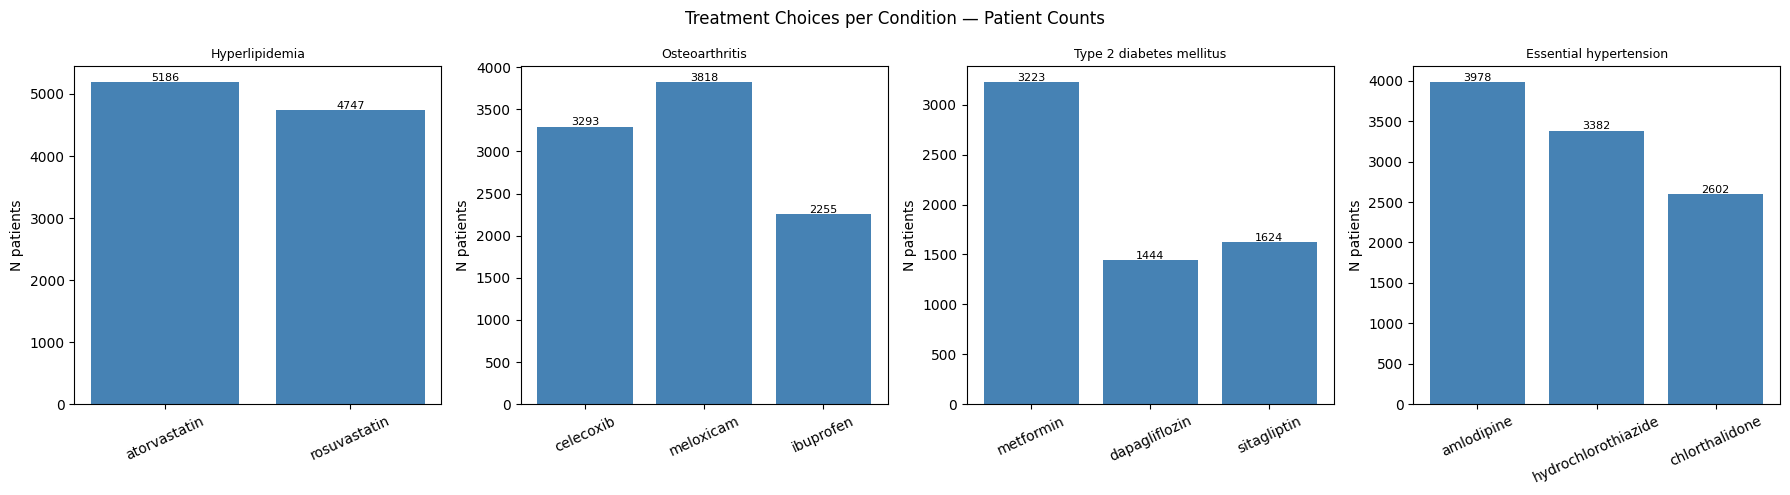

In [3]:

# For each condition with multiple treatments, how many patients per drug?
drug_groups = {
    "Hyperlipidemia":            ["atorvastatin", "rosuvastatin"],
    "Osteoarthritis":            ["celecoxib", "meloxicam", "ibuprofen"],
    "Type 2 diabetes mellitus":  ["metformin", "dapagliflozin", "sitagliptin"],
    "Essential hypertension":    ["amlodipine", "hydrochlorothiazide", "chlorthalidone"],
}

fig, axes = plt.subplots(1, len(drug_groups), figsize=(18, 5))

for ax, (condition, drugs) in zip(axes, drug_groups.items()):
    rows = []
    for drug in drugs:
        n = con.execute(f"""
            SELECT COUNT(DISTINCT de.person_id)
            FROM main.drug_exposure de
            JOIN main.concept cd ON de.drug_concept_id = cd.concept_id
            JOIN main.condition_occurrence co ON de.person_id = co.person_id
            JOIN main.concept cc ON co.condition_concept_id = cc.concept_id
            WHERE LOWER(cd.concept_name) LIKE '%{drug}%'
              AND cd.standard_concept = 'S'
              AND LOWER(cc.concept_name) LIKE '%{condition.lower()}%'
              AND cc.standard_concept = 'S'
        """).fetchone()[0]
        rows.append({'drug': drug, 'n': n})
    df_p = pd.DataFrame(rows)
    bars = ax.bar(df_p['drug'], df_p['n'], color='steelblue')
    ax.set_title(condition, fontsize=9)
    ax.set_ylabel('N patients')
    ax.tick_params(axis='x', rotation=25)
    for bar, row in zip(bars, rows):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 15,
                str(row['n']), ha='center', fontsize=8)

plt.suptitle('Treatment Choices per Condition — Patient Counts', fontsize=12)
plt.tight_layout()
plt.show()


## 16. Adverse Events Signal — New Conditions After Drug Initiation
For each drug, which conditions appear for the first time after the first prescription?
This is the empirical signal behind the causal question: *"what are the side effects of treatment choice A vs B?"*

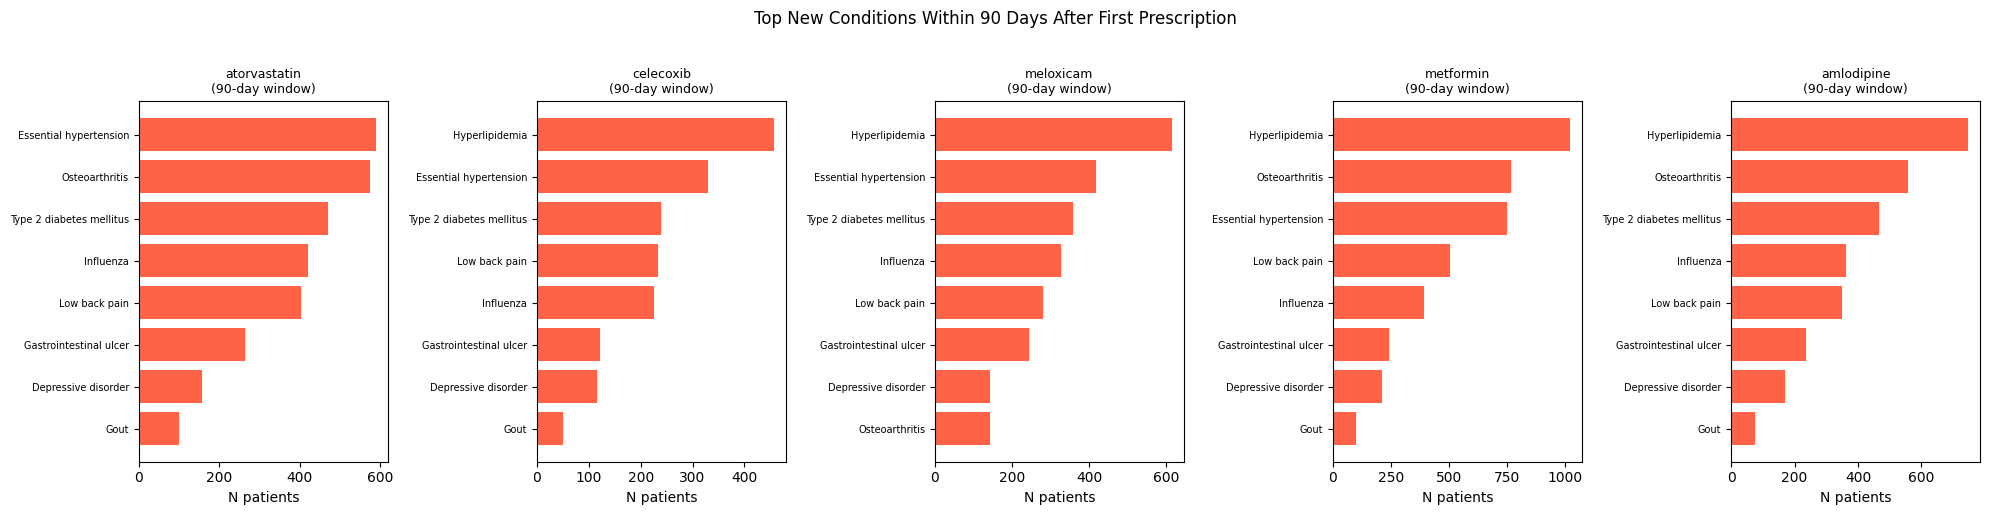

In [4]:

# For each top drug: what NEW conditions appear within 90 days after first prescription?
# "New" = not present in the patient's record before the drug start date

def get_new_conditions(drug_name, days=90, top_n=10):
    return con.execute(f"""
        WITH drug_starts AS (
            SELECT de.person_id, MIN(de.drug_exposure_start_date) AS drug_start
            FROM main.drug_exposure de
            JOIN main.concept c ON de.drug_concept_id = c.concept_id
            WHERE LOWER(c.concept_name) LIKE '%{drug_name.lower()}%'
              AND c.standard_concept = 'S'
            GROUP BY de.person_id
        ),
        new_conds AS (
            SELECT DISTINCT co.person_id, co.condition_concept_id
            FROM main.condition_occurrence co
            JOIN drug_starts ds ON co.person_id = ds.person_id
            WHERE co.condition_start_date >  ds.drug_start
              AND co.condition_start_date <= ds.drug_start + INTERVAL '{days} days'
              AND NOT EXISTS (
                  SELECT 1 FROM main.condition_occurrence co2
                  WHERE co2.person_id = co.person_id
                    AND co2.condition_concept_id = co.condition_concept_id
                    AND co2.condition_start_date <= ds.drug_start
              )
        )
        SELECT c.concept_name AS new_condition,
               COUNT(DISTINCT nc.person_id) AS n_patients,
               ROUND(COUNT(DISTINCT nc.person_id) * 100.0 /
                     (SELECT COUNT(DISTINCT person_id) FROM drug_starts), 1) AS pct_of_treated
        FROM new_conds nc
        JOIN main.concept c ON nc.condition_concept_id = c.concept_id
        WHERE c.standard_concept = 'S'
        GROUP BY c.concept_name
        ORDER BY n_patients DESC
        LIMIT {top_n}
    """).df()

# General scan: top 5 drugs × top new conditions
top_drugs_ae = ['atorvastatin', 'celecoxib', 'meloxicam', 'metformin', 'amlodipine']

fig, axes = plt.subplots(1, len(top_drugs_ae), figsize=(20, 5))
for ax, drug in zip(axes, top_drugs_ae):
    df_ae = get_new_conditions(drug, days=90, top_n=8)
    ax.barh(df_ae['new_condition'][::-1], df_ae['n_patients'][::-1], color='tomato')
    ax.set_title(f'{drug}\n(90-day window)', fontsize=9)
    ax.set_xlabel('N patients')
    ax.tick_params(axis='y', labelsize=7)

plt.suptitle('Top New Conditions Within 90 Days After First Prescription', fontsize=12, y=1.02)
plt.tight_layout()
plt.show()


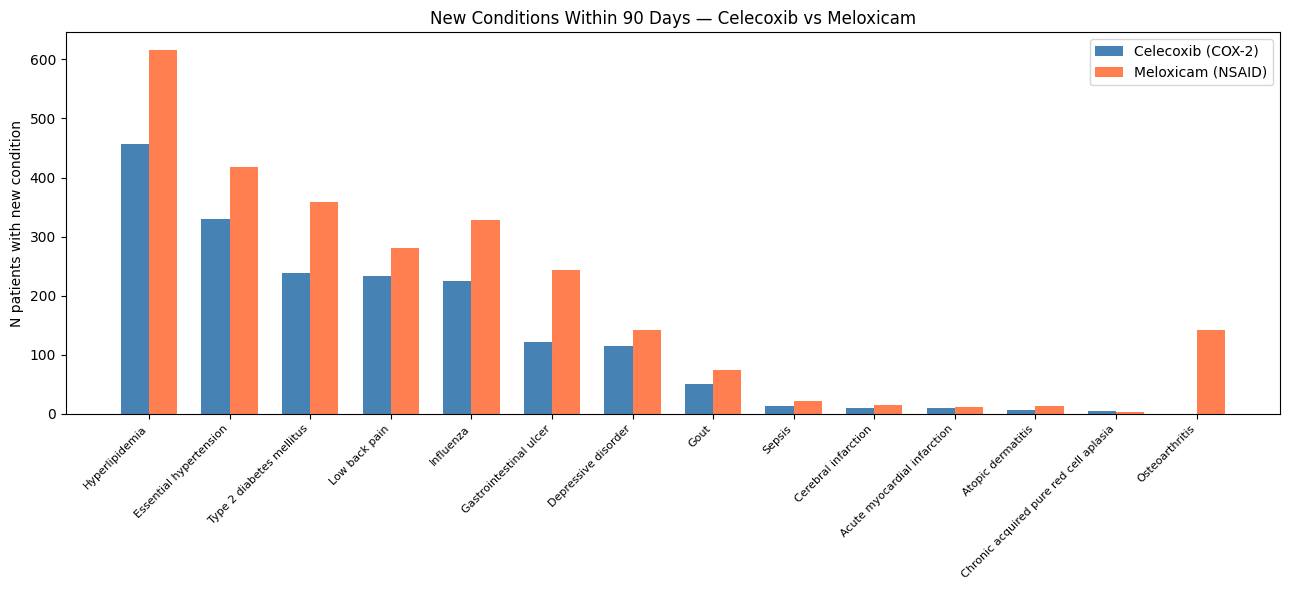

,new_condition,celecoxib,pct_celecoxib,meloxicam,pct_meloxicam
8,Hyperlipidemia,457.0,13.9,615,14.3
5,Essential hypertension,330.0,10.0,417,9.7
13,Type 2 diabetes mellitus,239.0,7.3,359,8.3
10,Low back pain,233.0,7.1,281,6.5
9,Influenza,225.0,6.8,328,7.6
6,Gastrointestinal ulcer,122.0,3.7,243,5.6
4,Depressive disorder,115.0,3.5,142,3.3
7,Gout,50.0,1.5,74,1.7
12,Sepsis,13.0,0.4,21,0.5
2,Cerebral infarction,10.0,0.3,15,0.3


In [5]:

# Targeted comparison: celecoxib vs meloxicam — differential new condition signal
df_cele = get_new_conditions('celecoxib', days=90, top_n=20).rename(
    columns={'n_patients': 'celecoxib', 'pct_of_treated': 'pct_celecoxib'})
df_melo = get_new_conditions('meloxicam', days=90, top_n=20).rename(
    columns={'n_patients': 'meloxicam', 'pct_of_treated': 'pct_meloxicam'})

df_compare = df_cele[['new_condition','celecoxib','pct_celecoxib']].merge(
    df_melo[['new_condition','meloxicam','pct_meloxicam']],
    on='new_condition', how='outer'
).fillna(0).sort_values('celecoxib', ascending=False).head(15)

fig, ax = plt.subplots(figsize=(13, 6))
x = range(len(df_compare))
w = 0.35
ax.bar([i - w/2 for i in x], df_compare['celecoxib'], w, label='Celecoxib (COX-2)', color='steelblue')
ax.bar([i + w/2 for i in x], df_compare['meloxicam'],  w, label='Meloxicam (NSAID)',  color='coral')
ax.set_xticks(list(x))
ax.set_xticklabels(df_compare['new_condition'], rotation=45, ha='right', fontsize=8)
ax.set_ylabel('N patients with new condition')
ax.set_title('New Conditions Within 90 Days — Celecoxib vs Meloxicam')
ax.legend()
plt.tight_layout()
plt.show()

df_compare


## 17. Measurements as Potential Outcomes
LDL, HbA1c, and systolic BP are available as continuous outcomes — richer signal than binary mortality.

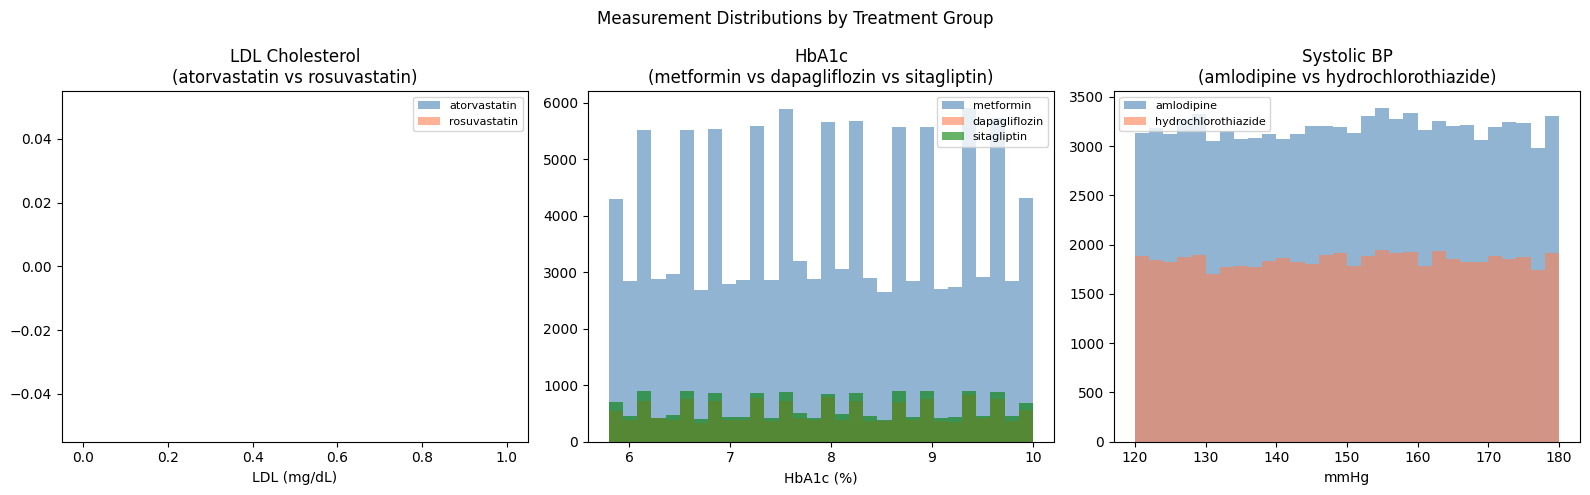

In [6]:

# Measurement distributions by treatment group
# Useful to assess whether measurements can serve as outcomes or confounders

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# LDL — atorvastatin vs rosuvastatin
for drug, color in [('atorvastatin', 'steelblue'), ('rosuvastatin', 'coral')]:
    vals = con.execute(f"""
        SELECT m.value_as_number
        FROM main.measurement m
        JOIN main.concept cm ON m.measurement_concept_id = cm.concept_id
        JOIN main.drug_exposure de ON m.person_id = de.person_id
        JOIN main.concept cd ON de.drug_concept_id = cd.concept_id
        WHERE cm.concept_code = '18262-6'
          AND LOWER(cd.concept_name) LIKE '%{drug}%'
          AND cd.standard_concept = 'S'
          AND m.value_as_number BETWEEN 20 AND 300
    """).df()['value_as_number']
    axes[0].hist(vals, bins=30, alpha=0.6, label=drug, color=color)
axes[0].set_title('LDL Cholesterol\n(atorvastatin vs rosuvastatin)')
axes[0].set_xlabel('LDL (mg/dL)')
axes[0].legend(fontsize=8)

# HbA1c — metformin vs dapagliflozin vs sitagliptin
for drug, color in [('metformin', 'steelblue'), ('dapagliflozin', 'coral'), ('sitagliptin', 'green')]:
    vals = con.execute(f"""
        SELECT m.value_as_number
        FROM main.measurement m
        JOIN main.concept cm ON m.measurement_concept_id = cm.concept_id
        JOIN main.drug_exposure de ON m.person_id = de.person_id
        JOIN main.concept cd ON de.drug_concept_id = cd.concept_id
        WHERE cm.concept_code = '4548-4'
          AND LOWER(cd.concept_name) LIKE '%{drug}%'
          AND cd.standard_concept = 'S'
          AND m.value_as_number BETWEEN 4 AND 15
    """).df()['value_as_number']
    axes[1].hist(vals, bins=30, alpha=0.6, label=drug, color=color)
axes[1].set_title('HbA1c\n(metformin vs dapagliflozin vs sitagliptin)')
axes[1].set_xlabel('HbA1c (%)')
axes[1].legend(fontsize=8)

# Systolic BP — amlodipine vs hydrochlorothiazide
for drug, color in [('amlodipine', 'steelblue'), ('hydrochlorothiazide', 'coral')]:
    vals = con.execute(f"""
        SELECT m.value_as_number
        FROM main.measurement m
        JOIN main.concept cm ON m.measurement_concept_id = cm.concept_id
        JOIN main.drug_exposure de ON m.person_id = de.person_id
        JOIN main.concept cd ON de.drug_concept_id = cd.concept_id
        WHERE cm.concept_code = '8480-6'
          AND LOWER(cd.concept_name) LIKE '%{drug}%'
          AND cd.standard_concept = 'S'
          AND m.value_as_number BETWEEN 80 AND 220
    """).df()['value_as_number']
    axes[2].hist(vals, bins=30, alpha=0.6, label=drug, color=color)
axes[2].set_title('Systolic BP\n(amlodipine vs hydrochlorothiazide)')
axes[2].set_xlabel('mmHg')
axes[2].legend(fontsize=8)

plt.suptitle('Measurement Distributions by Treatment Group', fontsize=12)
plt.tight_layout()
plt.show()


## 18. Co-morbidity Patterns
Which conditions frequently co-occur? This informs which confounders to expect in a causal model.

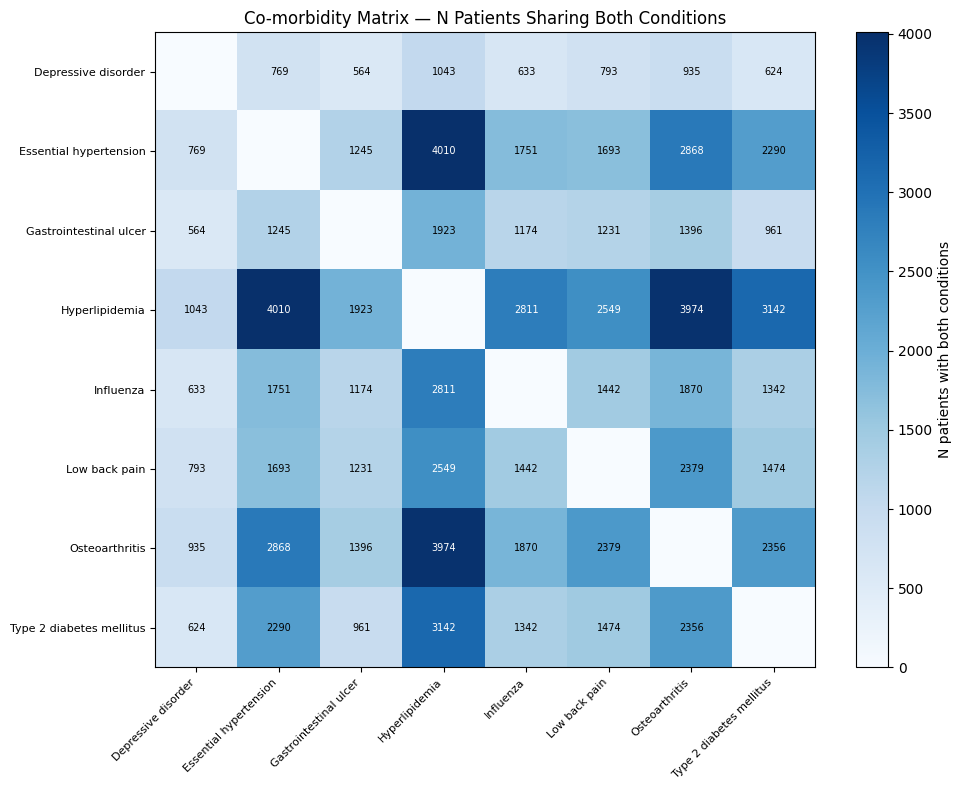

Top 10 co-morbidity pairs:


,condition_a,condition_b,n_patients
0,Essential hypertension,Hyperlipidemia,4010
1,Hyperlipidemia,Osteoarthritis,3974
2,Hyperlipidemia,Type 2 diabetes mellitus,3142
3,Essential hypertension,Osteoarthritis,2868
4,Hyperlipidemia,Influenza,2811
5,Hyperlipidemia,Low back pain,2549
6,Low back pain,Osteoarthritis,2379
7,Osteoarthritis,Type 2 diabetes mellitus,2356
8,Essential hypertension,Type 2 diabetes mellitus,2290
9,Gastrointestinal ulcer,Hyperlipidemia,1923


In [7]:

# Co-morbidity matrix: which conditions co-occur most frequently?
df_comorbidity = con.execute("""
    WITH patient_conds AS (
        SELECT DISTINCT co.person_id, c.concept_name AS condition
        FROM main.condition_occurrence co
        JOIN main.concept c ON co.condition_concept_id = c.concept_id
        WHERE c.standard_concept = 'S'
          AND c.concept_name IN (
              'Hyperlipidemia','Essential hypertension','Osteoarthritis',
              'Type 2 diabetes mellitus','Influenza','Low back pain',
              'Depressive disorder','Gastrointestinal ulcer'
          )
    )
    SELECT a.condition AS condition_a, b.condition AS condition_b,
           COUNT(DISTINCT a.person_id) AS n_patients
    FROM patient_conds a
    JOIN patient_conds b ON a.person_id = b.person_id AND a.condition < b.condition
    GROUP BY 1, 2
    ORDER BY n_patients DESC
""").df()

conditions = sorted(set(df_comorbidity['condition_a'].tolist() + df_comorbidity['condition_b'].tolist()))
matrix = pd.DataFrame(0, index=conditions, columns=conditions)
for _, row in df_comorbidity.iterrows():
    matrix.loc[row['condition_a'], row['condition_b']] = row['n_patients']
    matrix.loc[row['condition_b'], row['condition_a']] = row['n_patients']

fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(matrix.values, cmap='Blues', aspect='auto')
ax.set_xticks(range(len(conditions)))
ax.set_xticklabels(conditions, rotation=45, ha='right', fontsize=8)
ax.set_yticks(range(len(conditions)))
ax.set_yticklabels(conditions, fontsize=8)
plt.colorbar(im, ax=ax, label='N patients with both conditions')
ax.set_title('Co-morbidity Matrix — N Patients Sharing Both Conditions')
for i in range(len(conditions)):
    for j in range(len(conditions)):
        val = int(matrix.values[i, j])
        if val > 0:
            ax.text(j, i, str(val), ha='center', va='center', fontsize=7,
                    color='white' if val > matrix.values.max() * 0.6 else 'black')
plt.tight_layout()
plt.show()

print("Top 10 co-morbidity pairs:")
df_comorbidity.head(10)


In [21]:
con.close()
print('Connection closed.')

Connection closed.
